<a href="https://colab.research.google.com/github/Lavio-Bidolli/Organoids/blob/main/func_prot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computational science project
Bidolli Flavio\
Di Paoloemilio Matteo

In [ ]:
# Reload the session (Run notebook setup to connect the Drive Folder)
import dill
dill.load_session('notebook_env_new.db')

In [ ]:
# Save the session
import dill
dill.dump_session('notebook_env_new.db')

## Notebook setup

### Package installation

In [ ]:
# Shoud any package not be available, please use this cell
# Install python libraries
#   !pip install package_name
# Install system dependencies
#   !apt-get update
#   !apt-get install -y package_name
# Install the modern kmedoids package
!pip install kmedoids


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 476.3/476.3 kB 11.7 MB/s eta 0:00:00


### Google drive Mounting

In [ ]:
from google.colab import drive

# Drive mounting
drive.mount('/content/drive')

# Define the base path
base_path = '/content/drive/MyDrive/computational_science/'

import os
os.chdir(base_path)

# For testing
print("Files in the folder:")
!ls

Mounted at /content/drive
Files in the folder:
clustering_contingency.png
clustering_kmedoids_combined_contingency_10.png
clustering_kmedoids_combined_contingency_28.png
clustering_kmedoids_combined_contingency.png
clustering_kmedoids_combined_pca_10.png
clustering_kmedoids_combined_pca_28.png
clustering_kmedoids_combined_pca.png
clustering_kmedoids_combined_tsne_10.png
clustering_kmedoids_combined_tsne_28.png
clustering_kmedoids_combined_tsne.png
clustering_kmedoids_contingency.png
clustering_kmedoids_pca.png
clustering_kmedoids_tsne.png
clustering_test_contingency_firstpcs.png
clustering_test_contingency.png
clustering_test_firstpcs.png
clustering_test_kmedoids_combined_score_elbow.png
clustering_test_kmedoids_score_elbow.png
clustering_test_partial.png
clustering_test.png
clustering_test_tsne_firstpcs.png
clustering_test_tsne.png
confusion_matrix_test.png
confusion_matrix_training_set_logistic_regression.png
confusion_matrix_training_set.png
elbow_curve_10_pc.png
elbow_curve_10_proj

### Library imports

In [ ]:
import numpy as np
import scipy
import sklearn
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import kmedoids
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA
from scipy.stats import pearsonr
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px
import pandas as pd
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy import stats
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances
from sklearn.metrics import roc_curve, roc_auc_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import squareform
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

### Configuration

#### Plotting Style configuration

In [ ]:
import os # Ensure os is imported for path manipulation

# Rosé Pine colorscheme: something beautiful
# We download and apply the Rosé Pine Style to matplotlib
style_url = "https://raw.githubusercontent.com/h4pZ/rose-pine-matplotlib/main/themes/rose-pine-dawn.mplstyle"
!wget {style_url} -O rose-pine-dawn.mplstyle
plt.style.use(os.path.join(base_path, 'rose-pine-dawn.mplstyle'))

# Rose Pine Dawn variant
rose_pine_dawn = [
    "#faf4ed",  # very light background
    "#f2e9de",
    "#c9cbff",
    "#eb6f92",
    "#31748f",
    "#f6c177"
]

# Create a diverging colormap
rose_pine_palette = sns.color_palette(rose_pine_dawn, as_cmap=True)

--2026-01-14 11:06:00--  https://raw.githubusercontent.com/h4pZ/rose-pine-matplotlib/main/themes/rose-pine-dawn.mplstyle
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 40905 (40K) [text/plain]
Saving to: ‘rose-pine-dawn.mplstyle’

rose-pine-dawn.mpls 100%[===================>]  39.95K  --.-KB/s    in 0.05s   

2026-01-14 11:06:01 (828 KB/s) - ‘rose-pine-dawn.mplstyle’ saved [40905/40905]



## One-hot encoding of protein sequence data

In [ ]:
# I need the copies of the natural sequences before the OHE

def read_MSA(file_path, origin):

  with open(file_path) as f:
      records = f.read().split('>')[1:]

  sequences = []
  functional_flags = []
  ids = []

  origin = "nat" if origin == "natural" else "art" if origin == "artificial" else origin

  for rec in records:
      lines = rec.splitlines()
      header_parts = lines[0].split()
      seq_id = f"{header_parts[0]}_{origin}"
      label_str = header_parts[1]
      functional = label_str == "functional_true"
      sequence = ''.join(lines[1:])
      sequences.append(list(sequence))
      functional_flags.append(functional)
      ids.append(seq_id)

  seq_df = pd.DataFrame(sequences, columns=range(1, len(sequences[0]) + 1))
  seq_df.insert(0, 'functional', functional_flags)
  seq_df.insert(0, 'id', ids)
  return seq_df

MSA_nat='MSA_nat.faa'
MSA_art='MSA_art.faa'

# read natural sequences using the custom helper function
df_nat_raw = read_MSA(MSA_nat,origin="natural")

# read artificial sequences using the custom helper function
df_art_raw = read_MSA(MSA_art,origin="artificial")


AA = ['-','A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
aa_to_n = {aa: n for n, aa in enumerate(AA)}
n_to_aa = {n: aa for aa, n in aa_to_n.items()}

class SequenceDataset(Dataset):
    def __init__(self, df_sequences):
        self.sequences = df_sequences.replace(aa_to_n).values
        self.num_sequences = len(self.sequences)

    def __len__(self):
        return self.num_sequences

    def __getitem__(self, idx):
        return torch.tensor(self.sequences[idx], dtype=torch.long)

In [ ]:
def one_hot_encode(input_file_path):
  """
  Description: This function reads .faa files and perform one-hot encoding of the sequences.
  We shall assume that throuought the file the Fasta file format.
  """
  msa_characters = "A, C, D, E, F, G, H, I, K, L, M, N, P, Q, R, S, T, V, W, Y"
  msa_characters = msa_characters.split(", ")
  n = len(msa_characters)
  msa_dictionary = {'-': [0 for j in range(n)]}
  for idx, char in enumerate(msa_characters):
      msa_dictionary[char] = [1 if j == idx else 0 for j in range(n)]

  sequences = []
  functionality = []
  with open(input_file_path, 'r') as file:
    seq = []
    for line in file:
      reading = ''
      line = line.strip()

      if not line and not seq:
        continue
      elif not line and seq:
        sequences.append(seq)
        seq = []
        continue

      elif line.startswith('>'):
        reading = line.split('_')[-1]
        functionality.append(reading.lower()=='true')
      else:
        for char in line:
          seq.append(msa_dictionary[char])
  return np.array(sequences), np.array(functionality)


In [ ]:
X_debug,y_debug = one_hot_encode('MSA_test.faa') # file added for testing purposes
X,Y = one_hot_encode('MSA_nat.faa')
X_art,Y_art = one_hot_encode('MSA_art.faa')

In [ ]:
print(len(X[1,:]))

96


## Dimensional reduction and visualization of sequence space

### Preparatory tasks

In [ ]:
def flatten(X):
  """
  Description: this function is designed to flatten the data as a preliminary step to PCA.
  In our case, each sample will be a protein.
  Reshape fills the matrix row by row.
  """
  N_samples, L, A = X.shape
  return X.reshape(N_samples, L*A)

def perform_pca(X, n_components):
  """
  Description: this function performs pca and returns.
  """
  pca = PCA(n_components=n_components)
  pca.fit(X)
  return pca

### Performing PCA

In this context, due to one-hot encoding, after flattening the data our dataset has 96*20 features, each one representing the presence or absence of an amminoacid in a precise position. Clearly, on-site constraints enforce strong correlations between features associated to the same site: there cannot be a site with multiple ones appearing in one sample.\
A direction in the feature space is a weighted combination of aminoacids at different positions, capturing patterns across sequences. This also means that some principal components may actually have some interpretation, as they might have strong aminoacid selectivity at some sites.\
Now the flattened dataset is clearly not full rank, meaning that the data actually lives in a lower dimensional space, with many directions with zero covariance.\
Each principal component will explain only a little amount of variance. We also show that plotting PC1 vs PC2 whe observe little to no separation between functoinal and non functional sequences. The very same pattern is observed with artificial sequences.\

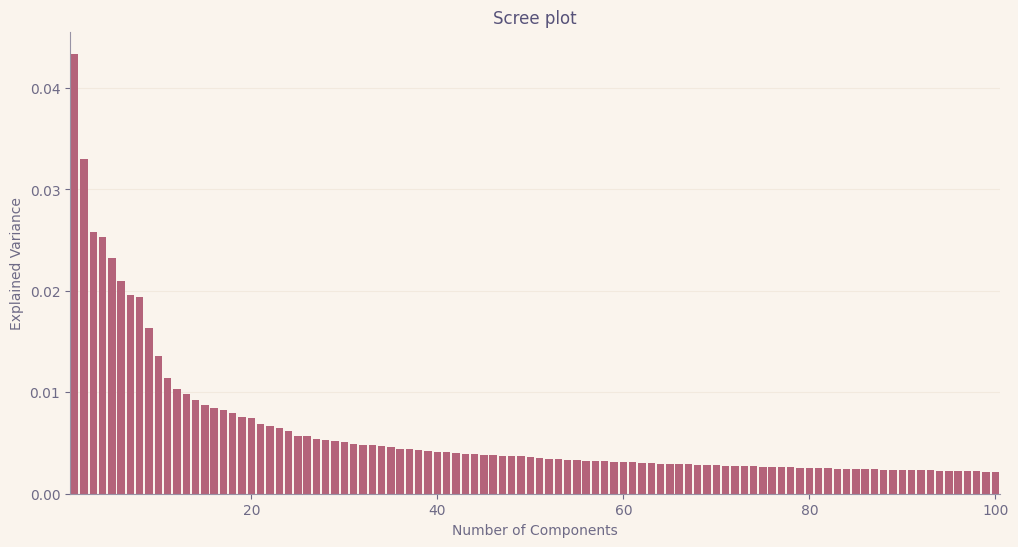

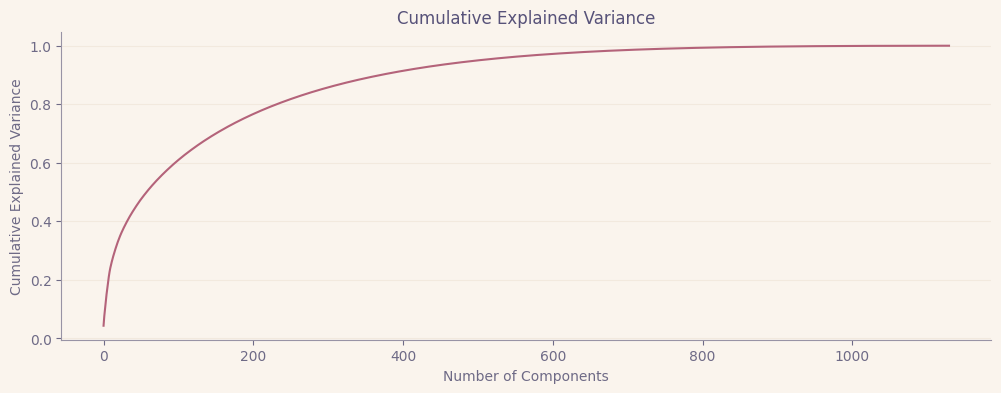

Cumultative explained variance by number of chosen principal components:
PC1: 4.3375%
PC10: 24.0471%
PC20: 32.9622%
PC30: 38.8376%
PC40: 43.3700%
PC50: 47.2059%
PC100: 60.7674%
PC150: 69.8511%
PC200: 76.5574%
PC300: 85.7063%
PC400: 91.3922%


In [ ]:
# Flatten the data and perform pca using previously defined functions
X_flat = flatten(X)
X_art_flat = flatten(X_art)

# Fit PCA without specifying the number of components to compute variance ratios for all components
pca_full = PCA().fit(X_flat)

# Plot the explained variance ratio for each principal component
fig=plt.figure(figsize=(12, 6))
plt.bar(range(1, len(pca_full.explained_variance_ratio_) + 1), pca_full.explained_variance_ratio_)
plt.xlabel('Number of Components')
plt.xlim(0.5, 100.5)
plt.ylabel('Explained Variance')
plt.title('Scree plot')
plt.savefig('pca_full_explained_variance.jpg', dpi=300, bbox_inches='tight')
plt.show()


# Plot the cumulative explained variance as a function of the number of components
fig=plt.figure(figsize=(12, 4))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_))  # Cumulative sum of explained variance
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.savefig('pca_full_cumulative_explained_variance.jpg', dpi=300, bbox_inches='tight')
plt.show()

print('Cumultative explained variance by number of chosen principal components:')
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
for i in [0, 9, 19, 29, 39, 49, 99, 149, 199, 299, 399]:
    print(f"PC{i+1}: {cumulative_variance[i]*100:.4f}%")

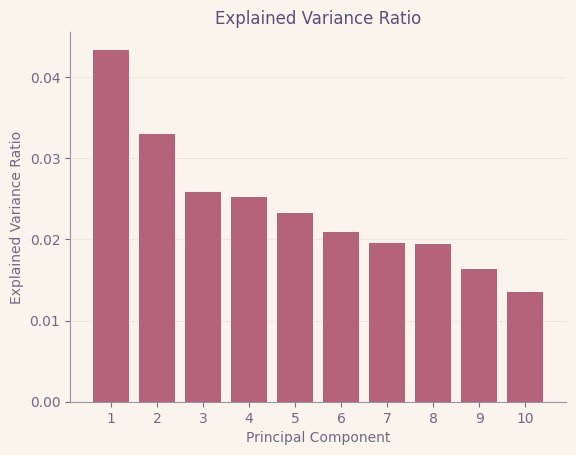

In [ ]:
pca = perform_pca(X_flat, 10)

# Get and plot the explained variance
variances = pca.explained_variance_ratio_
plt.xticks(ticks=range(1, len(variances) + 1))
plt.bar(range(1, len(variances) + 1), variances)
plt.title('Explained Variance Ratio')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.savefig('pca_explained_variance.jpg', dpi=300, bbox_inches='tight')
plt.show()

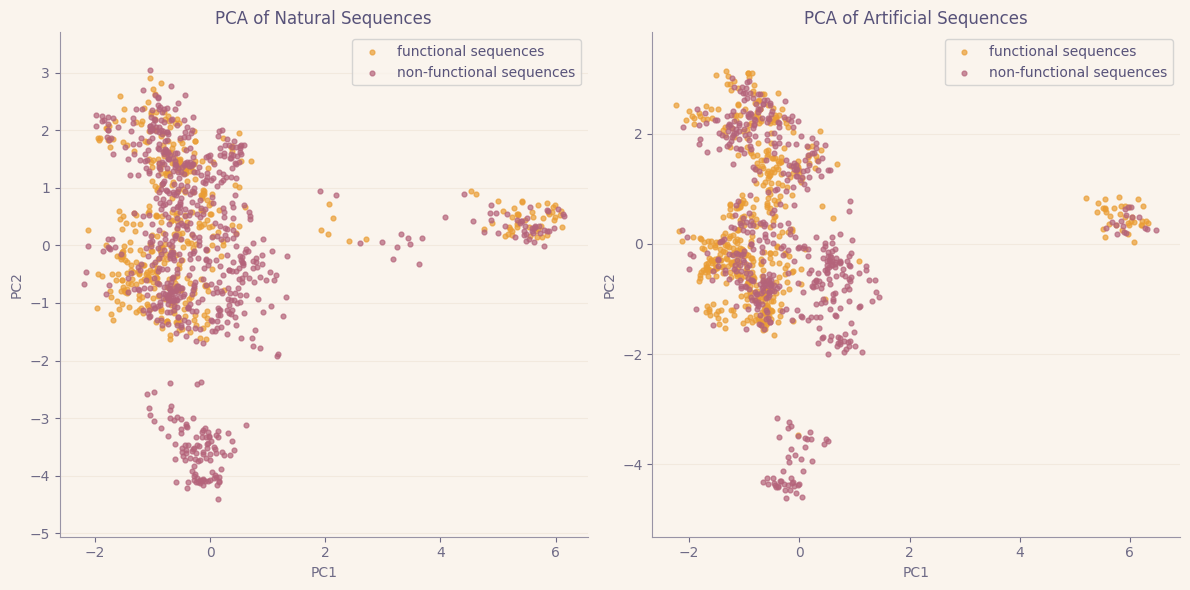

In [ ]:
# Projecting and plotting the first principal component against the second one
X_proj = pca.transform(X_flat)
X_art_proj = pca.transform(X_art_flat)

# Create some mask for the data
func_art = Y_art == 1
non_func_art = Y_art == 0
func_nat = Y == 1
non_func_nat = Y == 0

# Aesthetic
c_func = '#ea9d34'   # Gold (rose pine colorscheme)
c_non_func = '#b4637a' # Love (rose pine colorscheme)


# Plotting
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

ax2.scatter(X_art_proj[func_art, 0], X_art_proj[func_art, 1], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax2.scatter(X_art_proj[non_func_art, 0], X_art_proj[non_func_art, 1], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('PCA of Artificial Sequences')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 0], X_proj[func_nat, 1], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax1.scatter(X_proj[non_func_nat, 0], X_proj[non_func_nat, 1], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_title('PCA of Natural Sequences')
ax1.legend()
ax1.axis('equal') # Avoid distorsion

plt.tight_layout()
plt.savefig('pc1_vs_pc2.png', dpi=300, bbox_inches='tight')

plt.show()

### Further Investigation

#### Heatmap of the first principal components
A direction in the feature space is a weighted combination of aminoacids at different positions, capturing patterns across sequences. We may use Heat maps to interpret principal components.
Each PC weighs all the feature assigning them "loadings". Once a sample has been projected on the PC, we can compute its score by evaluating the weighed sum of its components (the weighs are the loadings).
Basically, samples with a large overlap with the PC will have low values for the feature with negative loadings and high values for the feature with positive loadings.
Data with high PC score will be projected far from the origin on the PC axis (on the positive or negative side).
For instance, from the previous graph, we see that all the samples with low (negative, but large in absolute value) score relative to the PC2 are non functional. The heat map has not proven to be useful, and the scores are not that easy to interpret as they are most often not driven by a single site.

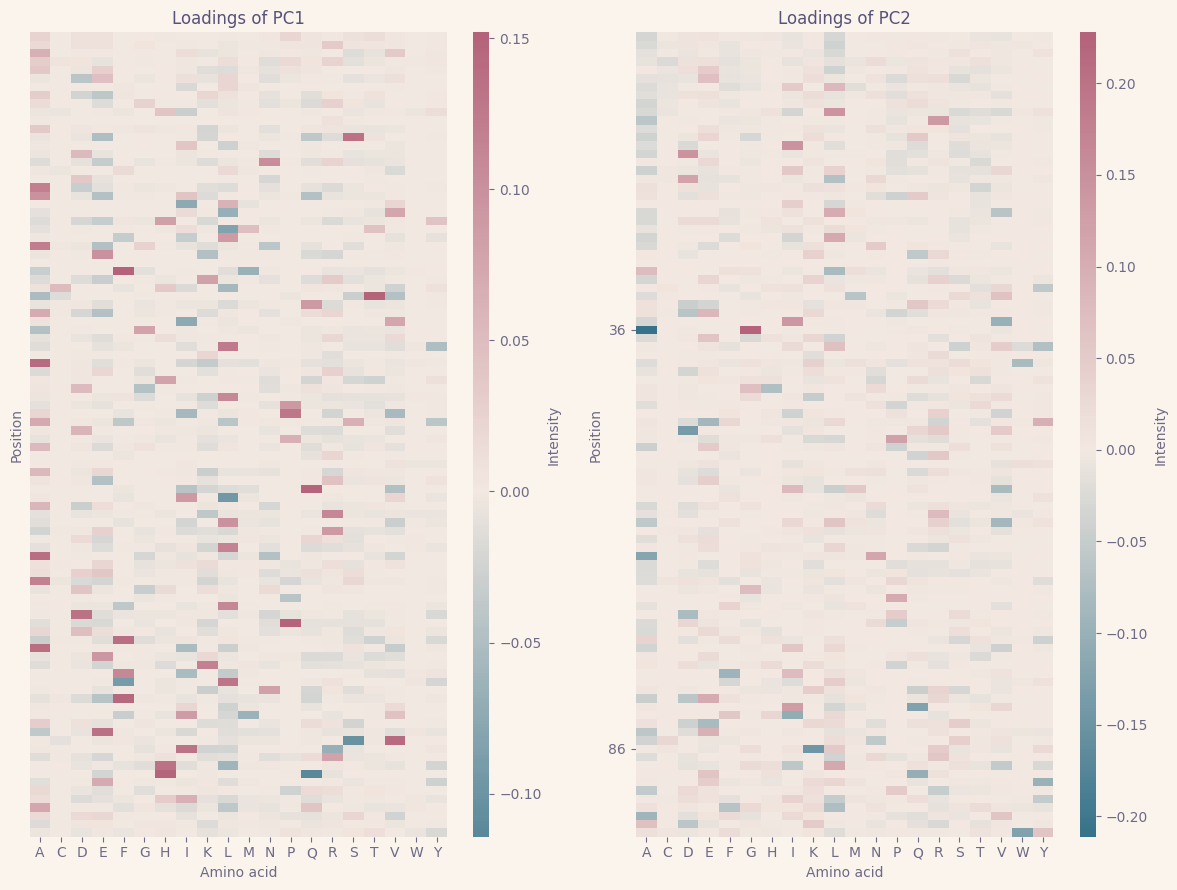

In [ ]:
# Reshape PC
pc1 = pca.components_[0].reshape(96, 20)  # PC1
pc2 = pca.components_[1].reshape(96, 20)  # PC2

# aesthetic
rose_pine_colors = ['#286983','#f2e9e1', '#b4637a']
cmap_rose = LinearSegmentedColormap.from_list("rose_pine_map", rose_pine_colors)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 9))  # 1 row, 2 columns

# PC1 heatmap
sns.heatmap(
    pc1,
    cmap=cmap_rose,
    center=0,
    xticklabels=list('ACDEFGHIKLMNPQRSTVWY'),
    yticklabels=False,
    cbar_kws={'label': 'Intensity', 'aspect': 50},
    ax=axes[0]
)
axes[0].set_xlabel('Amino acid')
axes[0].set_ylabel('Position')
axes[0].set_title('Loadings of PC1')

# PC2 heatmap
sns.heatmap(
    pc2,
    cmap=cmap_rose,
    center=0,
    xticklabels=list('ACDEFGHIKLMNPQRSTVWY'),
    yticklabels=False,
    cbar_kws={'label': 'Intensity', 'aspect': 50},
    ax=axes[1]
)

# Also mark position 36 (note that counting starts from zero)
axes[1].set_yticks([35.5, 85.5])
axes[1].set_yticklabels(['36', '86'])
axes[1].set_xlabel('Amino acid')
axes[1].set_ylabel('Position')
axes[1].set_title('Loadings of PC2')


plt.tight_layout()
plt.savefig('loadings_pc1_pc2.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def give_functionality(site, monomer, X, Y):
  """
  Description: this function gives how having a given monomer at a given site influences functionality.
  """
  count = 0
  function = 0

  msa_characters = "A, C, D, E, F, G, H, I, K, L, M, N, P, Q, R, S, T, V, W, Y"
  msa_characters = msa_characters.split(", ")
  idx = msa_characters.index(monomer)

  for i, sequence in enumerate(X):
      if sequence[site][idx] == 1:
        count += 1
        if Y[i]:
          function += 1
  if count == 0:
    ratio = 0
  else:
    ratio = (function/count)*100
  X_flat = flatten(X)
  r,p= pearsonr(X_flat[:,site*20 + idx], Y)
  if count != 0:
    print(f"Percentage of functional sequences with monomer {monomer} on site {site+1} in the dataset: {ratio:.2f}%")
    print(f"Pearson coefficient: r={r:.2f}, p-value: p={p}")
  else:
    print(f"No sequences with monomer {monomer} on site {site+1} in the dataset")

  return ratio, p, r

In [ ]:
give_functionality(site=35, monomer='A', X=X, Y=Y);

Percentage of functional sequences with monomer A on site 36 in the dataset: 30.79%
Pearson coefficient: r=-0.10, p-value: p=0.0010044945941486666


We see that functionality is indeed negatively correlated with A on site 36, which has a negative loading on PC2, though the result is quite weak (indeed, we need to have a largely negative score on PC2 to observe non functionality almost certainly, A36 only accounts for -0.2).

#### Identifying the most useful principal components
We want to achieve the best separation by looking at which principal components are correlated the most with the functionality.

In [ ]:
def give_score_correlation(X_proj, Y):
  """
  Description: this function gives the PC that correlates most with functionality, once
  a projected dataset is provided and labels are given.
  """
  # X_proj is a matrix whose lines are samples and rows are PC scores
  # The number of features in this matrix is the number of used principal components
  N = X_proj.shape[1]
  pearson_corr = []
  for i in range(N):
    pc_scores = X_proj[:, i]
    # The p value allows to compare with the null hypothesys
    #(chances that this correlation was accually obtained by pure noise. The lower, the better)
    r, p_value = pearsonr(pc_scores, Y)
    pearson_corr.append([i, r, abs(r), p_value])
  results = [entry for entry in pearson_corr if entry[3] <= 0.05]
  results.sort(key=lambda x: x[2], reverse=True)

  print("Most significant PCs:")
  for pc, r, abs_r, p in results[:6]:
    print(f"PC: {pc+1}, r: {r}, p: {p}")

  return

print("Looking at the firs 10 principal components...")
give_score_correlation(X_proj, Y);
print("\n")
print("For general purposes, we might look at all the components...")
X_proj_full = pca_full.transform(X_flat)
give_score_correlation(X_proj_full, Y);

Looking at the firs 10 principal components...
Most significant PCs:
PC: 3, r: 0.3686517865211772, p: 1.0655850236026103e-37
PC: 8, r: 0.190126709123482, p: 1.171489256868356e-10
PC: 2, r: 0.17175940123723274, p: 6.224326134762368e-09
PC: 4, r: -0.16262426307178235, p: 3.857063012793036e-08
PC: 7, r: 0.15571230415613957, p: 1.4353270684617634e-07
PC: 5, r: 0.06554935978468694, p: 0.027566286648898073


For general purposes, we might look at all the components...
Most significant PCs:
PC: 3, r: 0.3686519533189425, p: 1.0654990164253953e-37
PC: 8, r: 0.1901308302875066, p: 1.170391247161487e-10
PC: 2, r: 0.17175930772921266, p: 6.224445537599581e-09
PC: 4, r: -0.16262638598909337, p: 3.855473050385822e-08
PC: 7, r: 0.1557171952625447, p: 1.4340216624135208e-07
PC: 12, r: -0.14272166051202523, p: 1.4571409890321785e-06


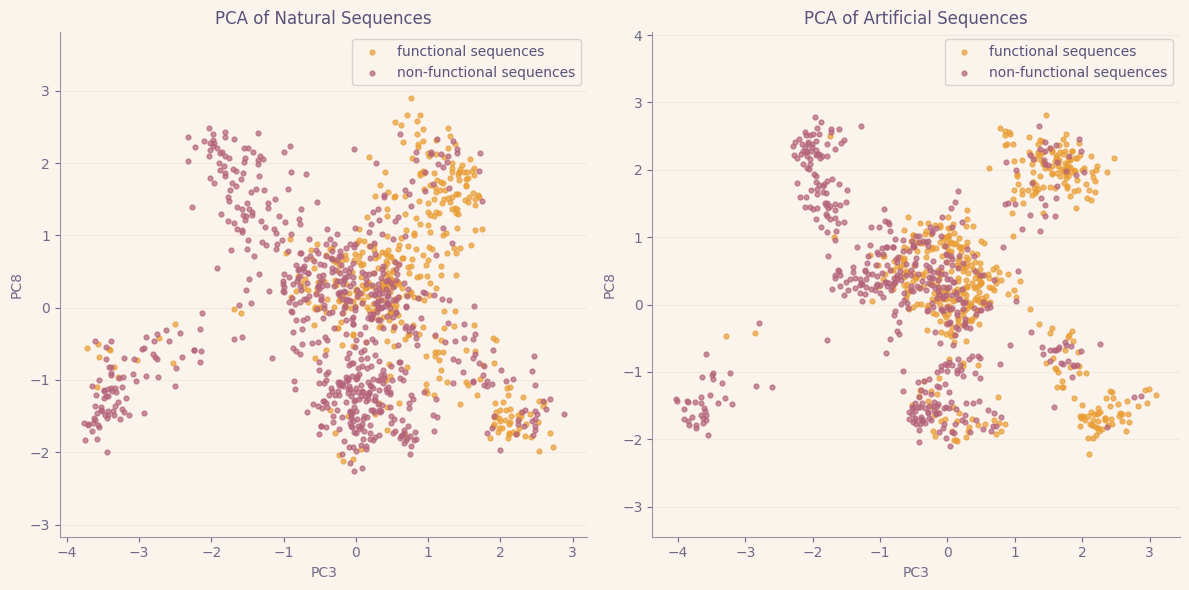

In [ ]:
# Create some mask for the data
func_art = Y_art == 1
non_func_art = Y_art == 0
func_nat = Y == 1
non_func_nat = Y == 0

# Plotting the most significant ones to check whether something useful emerges
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

ax2.scatter(X_art_proj[func_art, 2], X_art_proj[func_art, 7], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax2.scatter(X_art_proj[non_func_art, 2], X_art_proj[non_func_art, 7], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax2.set_xlabel('PC3')
ax2.set_ylabel('PC8')
ax2.set_title('PCA of Artificial Sequences')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 2], X_proj[func_nat, 7], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax1.scatter(X_proj[non_func_nat, 2], X_proj[non_func_nat, 7], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax1.set_xlabel('PC3')
ax1.set_ylabel('PC8')
ax1.set_title('PCA of Natural Sequences')
ax1.legend()
ax1.axis('equal') # Avoid distorsion

plt.tight_layout()
plt.savefig('pc3_vs_pc8.png', dpi=300, bbox_inches='tight')

plt.show()

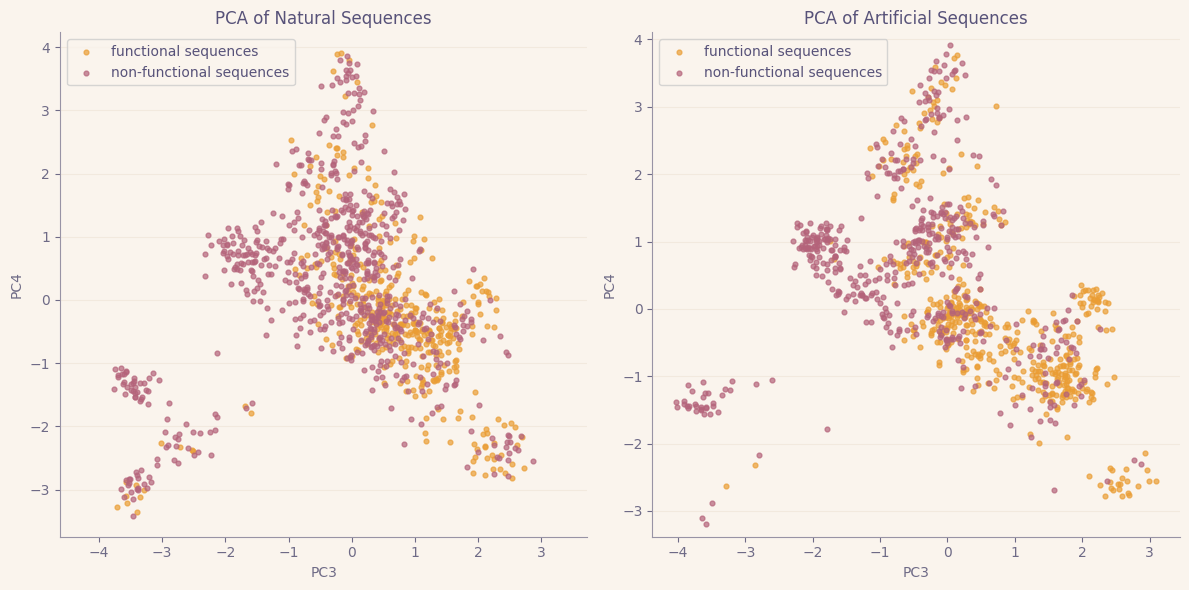

In [ ]:
# Create some mask for the data
func_art = Y_art == 1
non_func_art = Y_art == 0
func_nat = Y == 1
non_func_nat = Y == 0

# Plotting the most significant ones to check whether something useful emerges
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

ax2.scatter(X_art_proj[func_art, 2], X_art_proj[func_art, 3], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax2.scatter(X_art_proj[non_func_art, 2], X_art_proj[non_func_art, 3], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax2.set_xlabel('PC3')
ax2.set_ylabel('PC4')
ax2.set_title('PCA of Artificial Sequences')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 2], X_proj[func_nat, 3], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax1.scatter(X_proj[non_func_nat, 2], X_proj[non_func_nat, 3], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax1.set_xlabel('PC3')
ax1.set_ylabel('PC4')
ax1.set_title('PCA of Natural Sequences')
ax1.legend()
ax1.axis('equal') # Avoid distorsion

plt.tight_layout()
plt.savefig('pc3_vs_pc4.png', dpi=300, bbox_inches='tight')

plt.show()

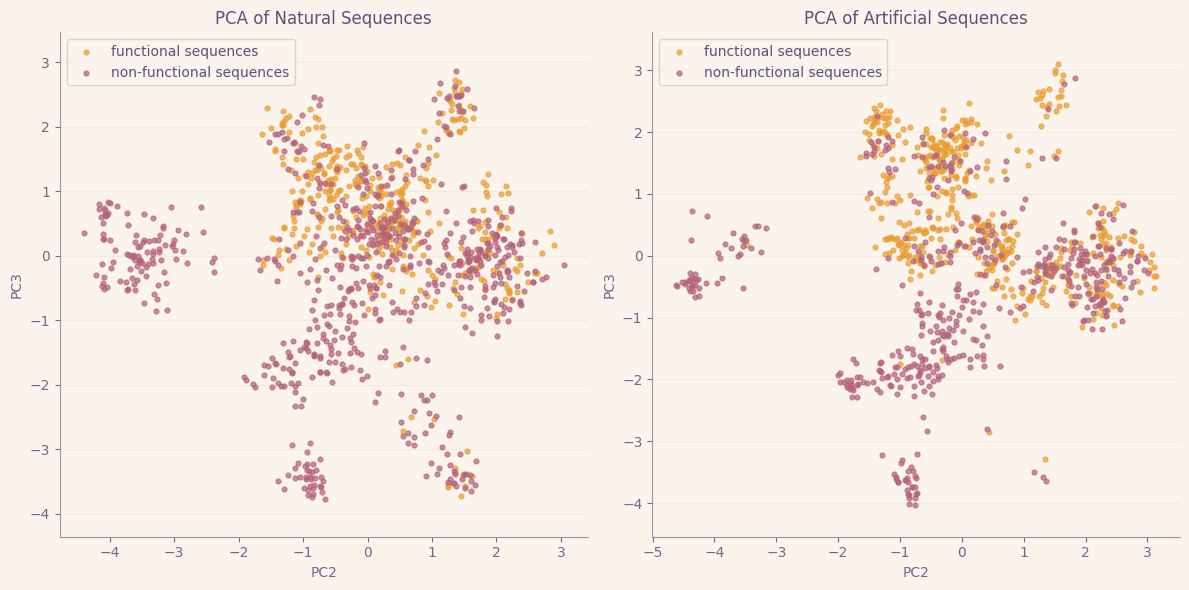

In [ ]:
# Create some mask for the data
func_art = Y_art == 1
non_func_art = Y_art == 0
func_nat = Y == 1
non_func_nat = Y == 0

# Plotting the most significant ones to check whether something useful emerges
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

ax2.scatter(X_art_proj[func_art, 1], X_art_proj[func_art, 2], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax2.scatter(X_art_proj[non_func_art, 1], X_art_proj[non_func_art, 2], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.set_title('PCA of Artificial Sequences')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 1], X_proj[func_nat, 2], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax1.scatter(X_proj[non_func_nat, 1], X_proj[non_func_nat, 2], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax1.set_xlabel('PC2')
ax1.set_ylabel('PC3')
ax1.set_title('PCA of Natural Sequences')
ax1.legend()
ax1.axis('equal') # Avoid distorsion

plt.tight_layout()
plt.savefig('pc2_vs_pc3.png', dpi=300, bbox_inches='tight')

plt.show()

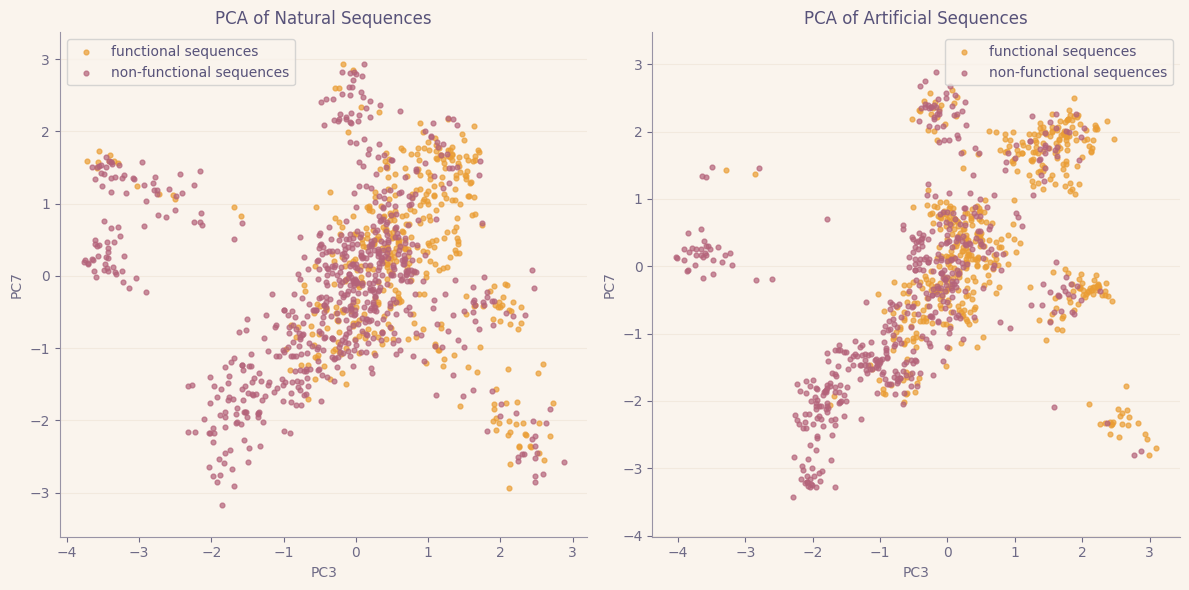

In [ ]:
# Create some mask for the data
func_art = Y_art == 1
non_func_art = Y_art == 0
func_nat = Y == 1
non_func_nat = Y == 0

# Plotting the most significant ones to check whether something useful emerges
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

ax2.scatter(X_art_proj[func_art, 2], X_art_proj[func_art, 6], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax2.scatter(X_art_proj[non_func_art, 2], X_art_proj[non_func_art, 6], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax2.set_xlabel('PC3')
ax2.set_ylabel('PC7')
ax2.set_title('PCA of Artificial Sequences')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 2], X_proj[func_nat, 6], s=12, alpha=0.7, c=c_func, label='functional sequences')
ax1.scatter(X_proj[non_func_nat, 2], X_proj[non_func_nat, 6], s=12, alpha=0.7, c=c_non_func, label='non-functional sequences')
ax1.set_xlabel('PC3')
ax1.set_ylabel('PC7')
ax1.set_title('PCA of Natural Sequences')
ax1.legend()
ax1.axis('equal') # Avoid distorsion

plt.tight_layout()
plt.savefig('pc3_vs_pc7.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# This code was AI generated but it is just to create an interactive 3d plot.
# I am not comfortable with this library at all
# 1. Prepare a DataFrame for Plotly
# We combine the 3 PCs and the Label into one table
# Indices: PC3 (idx 2), PC8 (idx 7), PC2 (idx 1)
df_plot = pd.DataFrame({
    'PC3': X_proj[:, 2],
    'PC8': X_proj[:, 7],
    'PC4': X_proj[:, 3],
    'Functionality': Y
})

# 2. Create the Interactive 3D Plot
fig = px.scatter_3d(
    df_plot,
    x='PC3',
    y='PC8',
    z='PC4',
    color='Functionality',
    color_continuous_scale='viridis',
    opacity=0.7,
    title='Interactive 3D PCA: PC3 vs PC8 vs PC4'
)

# 3. Tweak the marker size and look
fig.update_traces(marker=dict(size=4))

# 4. Force Equal Aspect Ratio (So it doesn't look distorted)
fig.update_layout(
    scene=dict(
        aspectmode='data' # This automatically scales axes equally
    )
)

fig.show()
fig.write_html("pca_3d_interactive.html")

#### Conclusions
Overall, we see that PC3 is crucuial for separating functionality of sequences.\
PC8 and PC4 follow: then, to project the dataset, our choice will fall into PC3vsPC4 or PC3vsPC8 depending on circumstances.\
It seems that PC3vsPC8 does a better job at highliting distinct "blobs" of data, that might be later identified as clusters. On the other hand PC3vsPC4 shows better, although not great, separation between functional and non functional sequences, especially on the generated ones.
We might provide a heatmap of PC3 to analyze its loadings.


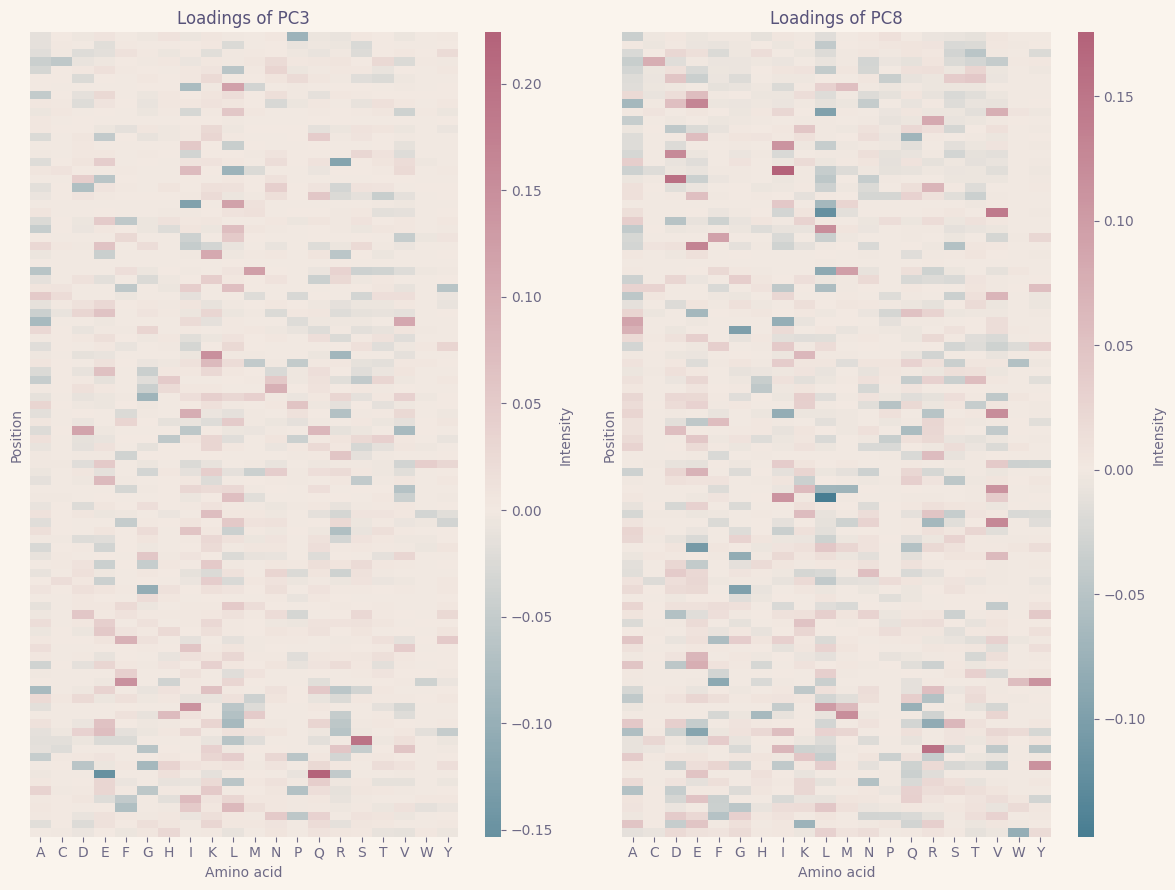

In [ ]:
# Reshape PC
pc3 = pca.components_[2].reshape(96, 20)  # PC1
pc8 = pca.components_[7].reshape(96, 20)  # PC2

# aesthetic
rose_pine_colors = ['#286983','#f2e9e1', '#b4637a']
cmap_rose = LinearSegmentedColormap.from_list("rose_pine_map", rose_pine_colors)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 9))  # 1 row, 2 columns

# PC3 heatmap
sns.heatmap(
    pc3,
    cmap=cmap_rose,
    center=0,
    xticklabels=list('ACDEFGHIKLMNPQRSTVWY'),
    yticklabels=False,
    cbar_kws={'label': 'Intensity', 'aspect': 50},
    ax=axes[0]
)
axes[0].set_xlabel('Amino acid')
axes[0].set_ylabel('Position')
axes[0].set_title('Loadings of PC3')

# PC8 heatmap
sns.heatmap(
    pc8,
    cmap=cmap_rose,
    center=0,
    xticklabels=list('ACDEFGHIKLMNPQRSTVWY'),
    yticklabels=False,
    cbar_kws={'label': 'Intensity', 'aspect': 50},
    ax=axes[1]
)

axes[1].set_xlabel('Amino acid')
axes[1].set_ylabel('Position')
axes[1].set_title('Loadings of PC8')


plt.tight_layout()
plt.savefig('loadings_pc3_pc8.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# It seems that the most important loadings are E and Q at position 89 for PC3.
# Indeed it seems like we are looking at significant more information here, compared to the last scenario.
give_functionality(site=88, monomer='E', X=X, Y=Y);
give_functionality(site=88, monomer='Q', X=X, Y=Y);
give_functionality(site=88, monomer='E', X=X_art, Y=Y_art);
give_functionality(site=88, monomer='Q', X=X_art, Y=Y_art);

Percentage of functional sequences with monomer E on site 89 in the dataset: 19.66%
Pearson coefficient: r=-0.25, p-value: p=1.956967631649328e-17
Percentage of functional sequences with monomer Q on site 89 in the dataset: 48.13%
Pearson coefficient: r=0.23, p-value: p=4.6898712099883245e-15
Percentage of functional sequences with monomer E on site 89 in the dataset: 24.45%
Pearson coefficient: r=-0.38, p-value: p=3.539217231622392e-36
Percentage of functional sequences with monomer Q on site 89 in the dataset: 64.26%
Pearson coefficient: r=0.33, p-value: p=3.596238052266982e-27


## Clustering sequence data
Dimensional reduction is crucial to be able to perform dimensional reduction on this dataset. The one hot encoded dataset is sparse, and made of zero and ones. Having a continuous space with limited dimensionality is necessary to introduce correctly concepts such as euclidean distance between points.\
For K-means algorithm we shall use a reduced number of principal components to use his norm, but this has limited applicability. This is evident when plotting the elbow curve: it is clear that there is no clear cut-off that would determine the number of clusters to use, unless one decides to consider only the first few principal components. This is however a strong dimensionality reduction.

#### Playing with K-MEANS

##### Elbow curves
This section was used to determine what number of components we should consider and how many clusters

In [ ]:
# We shall first try K means algorithm, which is the simplest choice.
# We introduce a function that performs elbow analysis to try different number of clusters.
def plot_elbow_curve(data, max_k=10, seed = None, n = 50):
    """
    Description: plot the elbow curve for K-means clustering up to max_k clusters.
    """
    inertia = [] # We shall save here the inertia to asses which works better
    for k in range(1, max_k+1):

        #Some comments on our choices are neccessary

        # init='k-means++' is standard for better convergence.
        # It is a convenient initialization where centroids are chose sequencially to be spread

        # n_init = 50 runs the algorithm multiple times with different initial conditions.
        # Recall that k-means is sensitive to initial conditions choice, so the algorithm is to be called multiple times to choose the best results.

        # The seed is set for reproducibility (first two digits of matr.)

        kmeans = KMeans(n_clusters=k, init='k-means++', n_init = n, random_state=seed)
        kmeans.fit(data)
        inertia.append(kmeans.inertia_)

    # Plotting
    fig = plt.figure(figsize=(14, 6))
    plt.plot(range(1, max_k+1), inertia, marker='o', linestyle='--')
    plt.title('Elbow curve')
    plt.xlabel('k')
    plt.ylabel('Inertia')
    plt.xticks(range(1, max_k+1))
    plt.grid(True)

    return fig

In [ ]:
fig = plot_elbow_curve(X_proj_full, max_k = 50, n= 10, seed = None)
fig.savefig('elbow_curve_full_pc.png', dpi=300, bbox_inches='tight')
plt.show()
# We can also set seed=None to test stability with respect to initial conditions
# Inertia is WCSS (Withing Cluster Sum of Squares)
# When using all the components, the notion of distance breaks down: indeed, we started from High-dimensional one-hot encoded data.
# When using all components, still we have removed some dimensions (those with null eigenvalue, zero variance), but this is not enough.
# We would need some continuous space.
# We can see from the Elbow curve that the number of clusters would be so high that we inevitably loose interpretability

KeyboardInterrupt: 

In [ ]:
fig = plot_elbow_curve(X_proj_full[:,0:10], max_k = 50, n= 50, seed = 34)
# This is the final plot and we fix a large number of initial conditions and use a fixed seed
fig.savefig('elbow_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
fig = plot_elbow_curve(X_proj_full[:,0:50], max_k = 50, n= 50, seed = 34)
# This is the final plot and we fix a large number of initial conditions and use a fixed seed
fig.savefig('elbow_curve_50pc.png', dpi=300, bbox_inches='tight')
plt.show()

##### Clustering by K-means

Using k-means to find 12 clusters
Plotting the clusters with PCA


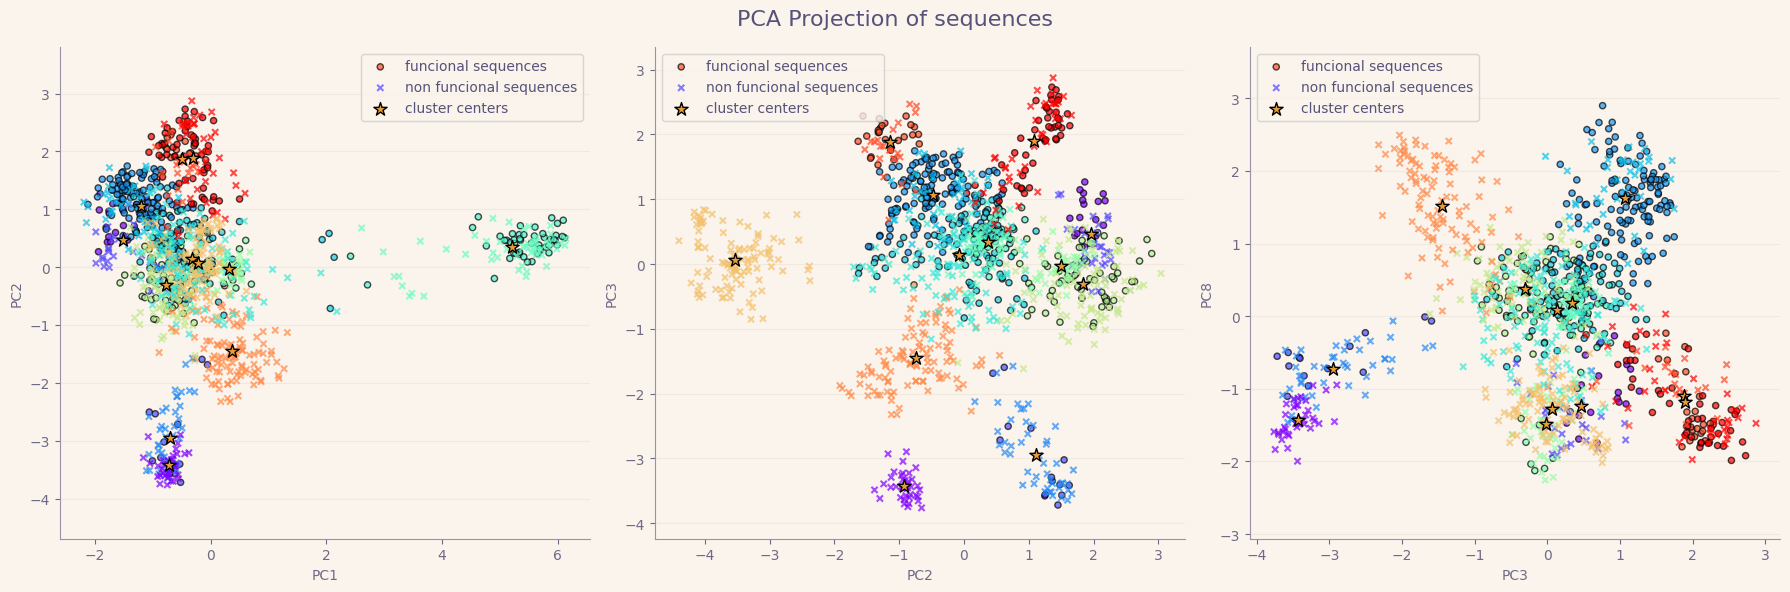

plotting using t-SNE


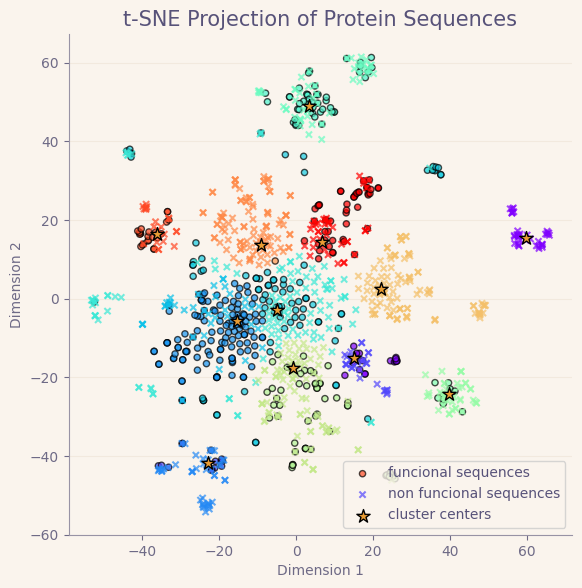

We shall now provide more information on how this clusters are related to functionality
There are 12 clusters.
Contingency Table for the generated clusters:
Is_Functional  False  True 
Cluster_ID                 
0                 37      0
1                 29     17
2                 46     14
3                 38    123
4                107     89
5                 52     48
6                 43      9
7                 87     54
8                103      0
9                105      1
10                22     23
11                38     45


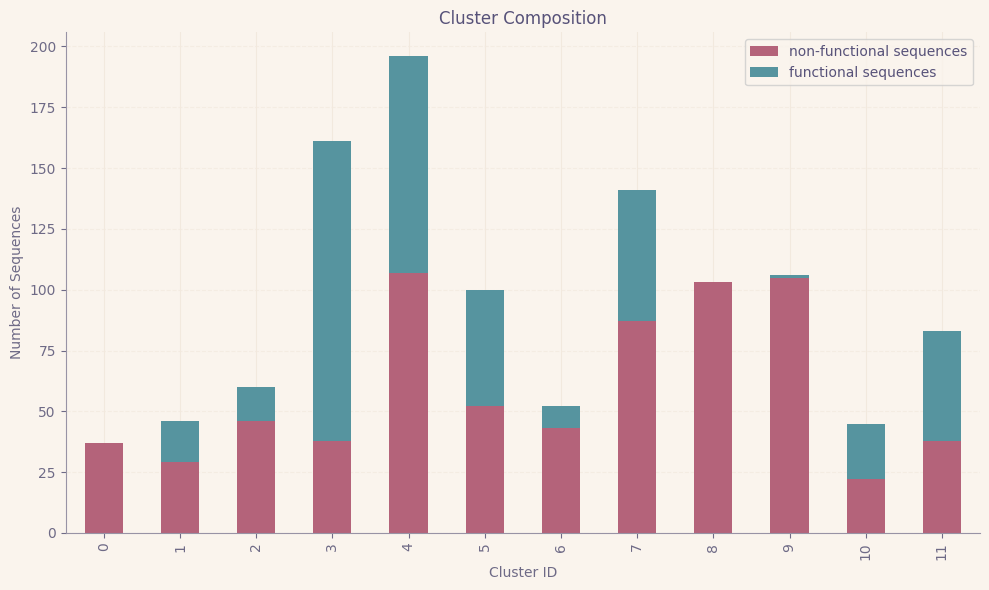

In [ ]:
# LARGE CLUSTERING SNIPPET
# The following snippet of code, which we decided not to put into a dedicated function, does the following:
# Performs KMeans algorithm with several initial conditions
# Plots clustering using different principal components and t-SNE
# We use a large number of initial conditions, but with fixed seed for reproducibility of the plot

# PERFORM K-MEANS
K = 12
est = KMeans(n_clusters = K, init='k-means++', n_init = 50, random_state=34)

# Fit the model to the data
est.fit(X_proj_full)

# Predict the cluster labels for the data points
y_kmeans = est.predict(X_proj_full)

# Provide cluster centers
centers = est.cluster_centers_

# PLOT STICKING TO PCA
print(f"Using k-means to find {K} clusters")
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj_full[func_nat, 2], X_proj_full[func_nat, 7], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax3.scatter(X_proj_full[non_func_nat, 2], X_proj_full[non_func_nat, 7], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax3.scatter(centers[:, 2], centers[:, 7], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'cluster centers')
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj_full[func_nat, 1], X_proj_full[func_nat, 2], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax2.scatter(X_proj_full[non_func_nat, 1], X_proj_full[non_func_nat, 2], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax2.scatter(centers[:, 1], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label= 'cluster centers')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj_full[func_nat, 0], X_proj_full[func_nat, 2], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax1.scatter(X_proj_full[non_func_nat, 0], X_proj_full[non_func_nat, 2], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax1.scatter(centers[:, 0], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'cluster centers')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_test.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# With t-SNE we cannot easily project new points. Then, we are forced to include the cluster centers in our dataset.
# We explect this not to change our picture much, because the cluster
combined_data = np.vstack((X_proj_full, centers))

# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(n_components=2, perplexity=10, learning_rate='auto', init='pca', random_state=34)
combined_tsne = tsne.fit_transform(combined_data)

# Separate the transformed data back into original data and cluster centers
X_tsne = combined_tsne[:-len(centers)]
mu_tsne = combined_tsne[-len(centers):]

plt.figure(figsize=(6.5, 6.5))

plt.scatter(X_tsne[func_nat, 0], X_tsne[func_nat, 1], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
plt.scatter(X_tsne[non_func_nat, 0], X_tsne[non_func_nat, 1], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
plt.scatter(mu_tsne[:,0], mu_tsne[:,1], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'cluster centers')
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_test_tsne.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmeans, 'Is_Functional': Y})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_Functional'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['non-functional sequences', 'functional sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('clustering_test_contingency.png', dpi=300, bbox_inches='tight')

plt.show()




In [ ]:
# LARGE CLUSTERING SNIPPET
# The following snippet of code, which we decided not to put into a dedicated function, does the following:
# Performs KMeans algorithm with several initial conditions
# Plots clustering using different principal components and t-SNE
# We use a large number of initial conditions, but with fixed seed for reproducibility of the plot

# PERFORM K-MEANS
K = 12
est = KMeans(n_clusters = K, init='k-means++', n_init = 50, random_state=34)

# Fit the model to the data
est.fit(X_proj)

# Predict the cluster labels for the data points
y_kmeans = est.predict(X_proj)

# Provide cluster centers
centers = est.cluster_centers_

# PLOT STICKING TO PCA
print(f"Using k-means to find {K} clusters")
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj_full[func_nat, 2], X_proj_full[func_nat, 7], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax3.scatter(X_proj_full[non_func_nat, 2], X_proj_full[non_func_nat, 7], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax3.scatter(centers[:, 2], centers[:, 7], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'cluster centers')
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj_full[func_nat, 1], X_proj_full[func_nat, 2], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax2.scatter(X_proj_full[non_func_nat, 1], X_proj_full[non_func_nat, 2], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax2.scatter(centers[:, 1], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label= 'cluster centers')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj_full[func_nat, 0], X_proj_full[func_nat, 2], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax1.scatter(X_proj_full[non_func_nat, 0], X_proj_full[non_func_nat, 2], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax1.scatter(centers[:, 0], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'cluster centers')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_test_firstpcs.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# With t-SNE we cannot easily project new points.
# Then, in this snippet we will not include centers, because they are object with reduced dimensionality and cannot be stacked
# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(n_components=2, perplexity=10, learning_rate='auto', init='pca', random_state=34)
combined_tsne = tsne.fit_transform(X_proj_full) # some bad notation inherited from the previous snippet

# Separate the transformed data back into original data and cluster centers
X_tsne = combined_tsne

plt.figure(figsize=(6.5, 6.5))

plt.scatter(X_tsne[func_nat, 0], X_tsne[func_nat, 1], s=20, alpha=0.7, c=y_kmeans[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
plt.scatter(X_tsne[non_func_nat, 0], X_tsne[non_func_nat, 1], s=20, alpha=0.7, c=y_kmeans[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_test_tsne_firstpcs.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmeans, 'Is_Functional': Y})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_Functional'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['non-functional sequences', 'functional sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('clustering_test_contingency_firstpcs.png', dpi=300, bbox_inches='tight')

plt.show()

#### Clustering with K-Medoids
We shall use K-Medoids, which allows to use any notion of distance. We then use Hamming distance, which measures the distance in terms of bite flips. It is useful to introduce a variant of hamming distance, which better considers mutations at different sites. Consider for instance, for two sites and three monomer types:
```
 sequence_A = [[1 0 0], [1 0 0 ]]
 sequence_B = [[0 0 0], [1 0 0 ]] # Deletion
 sequence_C = [[0 1 0], [1 0 0 ]] # Mutation
```
When dealing with the flattened vectors:
```
A = [1 0 0 1 0 0]
B = [0 0 0 1 0 0] # Hamming distance is 1
C = [0 1 0 1 0 0] # Hamming distance is 2
```
Consider how PAM works with k-medoids: proceeding this way will favour as medoids sequences with fewer mutations but more deletions. This is not what we want in this context. Then we shall use a precomputed distance that fixes this issue with the k-medoids algorithm.









In [ ]:
# Convert one-hot to categorical indices to simplify computation of edit distance
# gaps will be -1
X_cat = np.argmax(X, axis=2)
X_cat[X.sum(axis=2) == 0] = -1
dist_matrix = pairwise_distances(X_cat, metric=lambda a, b: np.sum(a != b))

In [ ]:
def evaluate_kmedoids(D, max_k=10):
    """
    Description: computes inertia and silhouette scores for K-medoids using a distance matrix.
    Plotting the results is useful to determine the right number of clusters.
    """
    inertia_scores = []
    silhouette_avg_scores = []
    k_range = range(2, max_k + 1)

    for k in k_range:
        # We use precomputed so that we can use the distance matrix
        #kmedoids = KMedoids(n_clusters=k, metric='precomputed', method='pam', init='build', random_state=34)
        kmedoids_model = kmedoids.KMedoids(n_clusters=k, random_state=34, method='fasterpam')
        kmedoids_model.fit(D)
        # Evaluate relevant quantities
        inertia_scores.append(kmedoids_model.inertia_)
        labels = kmedoids_model.labels_
        score = silhouette_score(D, labels, metric='precomputed')
        silhouette_avg_scores.append(score)

    return list(k_range), inertia_scores, silhouette_avg_scores

k_values, inertia, silhouette = evaluate_kmedoids(dist_matrix, max_k=30)

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_values, inertia, marker='o', color='b', linestyle='--')
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia (Total Cost)')
ax1.grid(True)
ax2.plot(k_values, silhouette, marker='s', color='r', linestyle='-')
ax2.set_title('Silhouette Score Analysis')
ax2.set_xlabel('Number of clusters (k)')
ax2.set_ylabel('Average Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.savefig('clustering_test_kmedoids_score_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

# Print the suggested k based on Silhouette
best_k = k_values[np.argmax(silhouette)]
print(f"Optimal number of clusters based on highest Silhouette Score: {best_k}")

In [ ]:
# PERFORM K-MEDOIDS
K = 10
kmedoids_model = kmedoids.KMedoids(n_clusters=K, random_state=34, method='fasterpam')
kmedoids_model.fit(dist_matrix)
y_kmedoids = kmedoids_model.labels_

# Provide cluster medoids
medoid_indices = kmedoids_model.medoid_indices_
centers = X_proj[medoid_indices]

# PLOT STICKING TO PCA
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj[func_nat, 2], X_proj[func_nat, 7], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax3.scatter(X_proj[non_func_nat, 2], X_proj[non_func_nat, 7], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax3.scatter(centers[:, 2], centers[:, 7], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj[func_nat, 1], X_proj[func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax2.scatter(X_proj[non_func_nat, 1], X_proj[non_func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax2.scatter(centers[:, 1], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label= 'medoids')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 0], X_proj[func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax1.scatter(X_proj[non_func_nat, 0], X_proj[non_func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax1.scatter(centers[:, 0], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_kmedoids_pca.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# Here we have no problems plotting the medoids, because they are part of the dataset
# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(metric='precomputed', n_components=2, perplexity=80, learning_rate='auto', init='random', random_state=34)
D_tsne = dist_matrix / np.max(dist_matrix) # Normalization often benefits t-SNE
X_tsne = tsne.fit_transform(D_tsne)
centroid_tsne = X_tsne[medoid_indices]

plt.figure(figsize=(6, 5))

plt.scatter(X_tsne[func_nat, 0], X_tsne[func_nat, 1], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
plt.scatter(X_tsne[non_func_nat, 0], X_tsne[non_func_nat, 1], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
plt.scatter(centroid_tsne[:,0], centroid_tsne[:,1], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_kmedoids_tsne.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality.")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmedoids, 'Is_Functional': Y})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_Functional'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['non-functional sequences', 'functional sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_xticklabels(range(1, len(contingency_table) + 1), rotation=0)
plt.tight_layout()
plt.savefig('clustering_kmedoids_contingency.png', dpi=300, bbox_inches='tight')

plt.show()

#### K-Medoids with the combined dataset

In [ ]:
# We shall start by computing the distance matrix from the dataset X
T = np.vstack((X,X_art))
T_cat = np.argmax(T, axis=2)
T_cat[T.sum(axis=2) == 0] = -1
dist_matrix_combined = pairwise_distances(T_cat, metric=lambda a, b: np.sum(a != b))

In [ ]:
k_values, inertia, silhouette = evaluate_kmedoids(dist_matrix_combined, max_k=50)

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_values, inertia, marker='o', color='b', linestyle='--')
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia (Total Cost)')
ax1.grid(True)
ax2.plot(k_values, silhouette, marker='s', color='r', linestyle='-')
ax2.set_title('Silhouette Score Analysis')
ax2.set_xlabel('Number of clusters (k)')
ax2.set_ylabel('Average Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.savefig('clustering_test_kmedoids_combined_score_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

best_k = k_values[np.argmax(silhouette)]
print(f"Optimal number of clusters based on highest Silhouette Score: {best_k}")

The previous graph can be interpreted in the following way: the artificial sequences successfully filled the gaps between families of natural sequences. This means that the silhouette score has a steep increase.

In [ ]:
# PERFORM K-MEDOIDS
K = 26
kmedoids_model = kmedoids.KMedoids(n_clusters=K, metric='precomputed', method='pam', init='build', random_state=34)
kmedoids_model.fit(dist_matrix_combined)
y_kmedoids_combined = kmedoids_model.labels_
Z = X.shape[0]
J = X_art.shape[0]
y_kmedoids = y_kmedoids_combined[:Z]
y_kmedoids_art = y_kmedoids_combined[Z:]

medoid_indices_combined = kmedoids_model.medoid_indices_
T_proj = np.vstack((X_proj,X_art_proj))
centers = T_proj[medoid_indices_combined]

# PLOT STICKING TO PCA
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj[:, 2], X_proj[:, 7], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="nipy_spectral", edgecolors='black', linewidth=1)
ax3.scatter(X_art_proj[:, 2], X_art_proj[:, 7], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="nipy_spectral")
ax3.scatter(centers[:, 2], centers[:, 7], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj[:, 1], X_proj[:, 2], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="nipy_spectral", edgecolors='black', linewidth=1)
ax2.scatter(X_art_proj[:, 1], X_art_proj[:,2], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="nipy_spectral")
ax2.scatter(centers[:, 1], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[:, 0], X_proj[:, 2], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="nipy_spectral", edgecolors='black', linewidth=1)
ax1.scatter(X_art_proj[:, 0], X_art_proj[:, 2], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="nipy_spectral")
ax1.scatter(centers[:, 0], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_kmedoids_combined_pca_28.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# Here we have no problems plotting the medoids, because they are part of the dataset
# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(metric='precomputed', n_components=2, perplexity=30, learning_rate='auto', init='random', random_state=34)
D_tsne_combined = dist_matrix_combined / np.max(dist_matrix_combined) # Normalization often benefits t-SNE
X_tsne_combined = tsne.fit_transform(D_tsne_combined)
centroid_tsne_combined = X_tsne_combined[medoid_indices_combined]

plt.figure(figsize=(6, 5))

plt.scatter(X_tsne_combined[:Z, 0], X_tsne_combined[:Z, 1], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="nipy_spectral", edgecolors='black', linewidth=1)
plt.scatter(X_tsne_combined[Z:, 0], X_tsne_combined[Z:, 1], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="nipy_spectral")
plt.scatter(centroid_tsne_combined[:, 0], centroid_tsne_combined[:, 1], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_kmedoids_combined_tsne_28.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality.")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmedoids_combined, 'Is_artificial': np.hstack([np.ones(Z), np.zeros(J)])})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_artificial'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['Artificial Sequences', 'Natural Sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_xticklabels(range(1, len(contingency_table) + 1), rotation=0)
plt.tight_layout()
plt.savefig('clustering_kmedoids_combined_contingency_28.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# PERFORM K-MEDOIDS
K = 10
kmedoids_model = kmedoids.KMedoids(n_clusters=K, metric='precomputed', method='pam', init='build', random_state=34)
kmedoids_model.fit(dist_matrix_combined)
y_kmedoids_combined = kmedoids_model.labels_
Z = X.shape[0]
J = X_art.shape[0]
y_kmedoids = y_kmedoids_combined[:Z]
y_kmedoids_art = y_kmedoids_combined[Z:]

medoid_indices_combined = kmedoids_model.medoid_indices_
T_proj = np.vstack((X_proj,X_art_proj))
centers = T_proj[medoid_indices_combined]

# PLOT STICKING TO PCA
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj[:, 2], X_proj[:, 7], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax3.scatter(X_art_proj[:, 2], X_art_proj[:, 7], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="rainbow")
ax3.scatter(centers[:, 2], centers[:, 7], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj[:, 1], X_proj[:, 2], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax2.scatter(X_art_proj[:, 1], X_art_proj[:,2], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="rainbow")
ax2.scatter(centers[:, 1], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[:, 0], X_proj[:, 2], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax1.scatter(X_art_proj[:, 0], X_art_proj[:, 2], s=30, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="rainbow")
ax1.scatter(centers[:, 0], centers[:, 2], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_kmedoids_combined_pca_10.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# Here we have no problems plotting the medoids, because they are part of the dataset
# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(metric='precomputed', n_components=2, perplexity=30, learning_rate='auto', init='random', random_state=34)
D_tsne_combined = dist_matrix_combined / np.max(dist_matrix_combined) # Normalization often benefits t-SNE
X_tsne_combined = tsne.fit_transform(D_tsne_combined)
centroid_tsne_combined = X_tsne_combined[medoid_indices_combined]

plt.figure(figsize=(7, 6))

plt.scatter(X_tsne_combined[:Z, 0], X_tsne_combined[:Z, 1], s=20, alpha=0.7, c=y_kmedoids, label = 'natural sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
plt.scatter(X_tsne_combined[Z:, 0], X_tsne_combined[Z:, 1], s=20, alpha=0.7, c=y_kmedoids_art, label = 'artificial sequences', marker = 'v', cmap="rainbow")
plt.scatter(centroid_tsne_combined[:, 0], centroid_tsne_combined[:, 1], s=100, color="#ea9d34", marker='*', edgecolors='black', linewidth=1, label = 'medoids')
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_kmedoids_combined_tsne_10.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality.")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmedoids_combined, 'Is_artificial': np.hstack([np.ones(Z), np.zeros(J)])})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_artificial'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['Artificial Sequences', 'Natural Sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_xticklabels(range(1, len(contingency_table) + 1), rotation=0)
plt.tight_layout()
plt.savefig('clustering_kmedoids_combined_contingency_10.png', dpi=300, bbox_inches='tight')

plt.show()

#### Hierarchical Clustering (Rough trial, aborted)

In [ ]:
# Plot dendogram with precomputed matrix
condensed_dist = squareform(dist_matrix)
Z = linkage(condensed_dist, method='complete')
plt.figure(figsize=(15, 15))
dendrogram(Z)
plt.show()

In [ ]:
# Implementation using the t=80 threshold
from scipy.cluster.hierarchy import fcluster

# criterion='distance' uses the Y-axis value
labels = fcluster(Z, t=75.4, criterion='distance')

print(f"Number of clusters found: {len(set(labels))}")

y_kmedoids = labels

# PLOT STICKING TO PCA
print("Plotting the clusters with PCA")
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
fig.suptitle("PCA Projection of sequences", fontsize=16)

ax3.scatter(X_proj[func_nat, 2], X_proj[func_nat, 7], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax3.scatter(X_proj[non_func_nat, 2], X_proj[non_func_nat, 7], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax3.set_xlabel('PC3')
ax3.set_ylabel('PC8')
ax3.legend()
ax3.axis('equal') # Avoid distorsion

ax2.scatter(X_proj[func_nat, 1], X_proj[func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax2.scatter(X_proj[non_func_nat, 1], X_proj[non_func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax2.set_xlabel('PC2')
ax2.set_ylabel('PC3')
ax2.legend()
ax2.axis('equal') # Avoid distorsion

ax1.scatter(X_proj[func_nat, 0], X_proj[func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
ax1.scatter(X_proj[non_func_nat, 0], X_proj[non_func_nat, 2], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend()
ax1.axis('equal')

plt.tight_layout()
plt.savefig('clustering_kmedoids_pca.png', dpi=300, bbox_inches='tight')

plt.show()

# PLOT USING t-SNE
print("plotting using t-SNE")
# Here we have no problems plotting the medoids, because they are part of the dataset
# Perplexity was set euristically, looking at the number which achieves best separation without creating dense blobs
tsne = TSNE(metric='precomputed', n_components=2, perplexity=80, learning_rate='auto', init='random', random_state=34)
D_tsne = dist_matrix / np.max(dist_matrix) # Normalization often benefits t-SNE
X_tsne = tsne.fit_transform(D_tsne)

plt.figure(figsize=(6, 5))

plt.scatter(X_tsne[func_nat, 0], X_tsne[func_nat, 1], s=20, alpha=0.7, c=y_kmedoids[func_nat], label = 'funcional sequences', marker = 'o', cmap="rainbow", edgecolors='black', linewidth=1)
plt.scatter(X_tsne[non_func_nat, 0], X_tsne[non_func_nat, 1], s=20, alpha=0.7, c=y_kmedoids[non_func_nat], label = 'non funcional sequences', marker = 'x', cmap="rainbow")
plt.title('t-SNE Projection of Protein Sequences', fontsize=15)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.savefig('clustering_kmedoids_tsne.png', dpi=300, bbox_inches='tight')

plt.show()

# MAKE SOME ANALYSIS ON THE RESULTING CLUSTERS
print("We shall now provide more information on how this clusters are related to functionality.")
print(f"There are {K} clusters.")
# Create a dataframe from a dictionary
df = pd.DataFrame({'Cluster_ID': y_kmedoids, 'Is_Functional': Y})
# Generate the contingency table (to address the problem of purity of clusters)
contingency_table = pd.crosstab(df['Cluster_ID'], df['Is_Functional'])
# Print the result
print("Contingency Table for the generated clusters:")
print(contingency_table)
# Plotting
plt.figure(figsize=(10, 6))
contingency_table.plot(kind='bar', stacked=True, color=['#b4637a','#56949f'], ax=plt.gca())

plt.title('Cluster Composition')
plt.ylabel('Number of Sequences')
plt.xlabel('Cluster ID')
plt.legend(labels=['non-functional sequences', 'functional sequences'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.gca().set_xticklabels(range(1, len(contingency_table) + 1), rotation=0)
plt.tight_layout()
plt.savefig('clustering_kmedoids_contingency.png', dpi=300, bbox_inches='tight')

plt.show()



In [ ]:
t_values = np.linspace(65, 95, 50)  # Adjust '10' based on your minimum meaningful distance

silhouette_scores = []
valid_t_values = [] # To keep track of t values that actually produced valid clusters

print("Scanning thresholds...")

for t in t_values:
    # 2. Cut by Distance
    labels = fcluster(Z, t=t, criterion='distance')

    # Check number of clusters
    n_clusters = len(set(labels))

    # Silhouette score is only valid if we have between 2 and N-1 clusters
    if 1 < n_clusters < len(dist_matrix):
        score = silhouette_score(dist_matrix, labels, metric='precomputed')
        silhouette_scores.append(score)
        valid_t_values.append(t)
    else:
        # If t is too high (1 cluster) or too low (all singletons), skip
        pass

# 3. Plot Score vs Distance Threshold
plt.figure(figsize=(10, 6))
plt.plot(valid_t_values, silhouette_scores, marker='o', color='purple')

plt.title('Silhouette Score vs. Cut Height (t)')
plt.xlabel('Distance Threshold (t)')
plt.ylabel('Silhouette Score')
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight the best cut
if silhouette_scores:
    best_idx = np.argmax(silhouette_scores)
    best_t = valid_t_values[best_idx]
    best_score = silhouette_scores[best_idx]
    plt.axvline(x=best_t, color='red', linestyle='--', label=f'Optimal t ≈ {best_t:.1f}')
    plt.legend()

plt.show()

print(f"Optimal cut height is approximately: {best_t:.2f}")

## Predicting protein functionality

In [ ]:
# Randomly devide the dataset of natural sequences into a train and test parts
# Stratification is used so that the chosen train and test datasets are representative and meaningful
# Stratification enforces the ratio of functional sequences to be the same as the original dataset
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=34, stratify=Y)

### Random Forest

In [ ]:
ratio = np.sum(Y_train == 0) / len(Y_train)
print(f"The ratio of nonfunctional sequences in the training set is: {ratio}")
# There are more non-functional than functional sequences in the dataset, hence balanced accuracy is reccomended

The ratio of nonfunctional sequences in the training set is: 0.6261061946902655


In [ ]:
# We shall perform grid search to determine the best parameters for the model.
# In this phase, the training set gets further devided
grid = {
    'n_estimators':[100, 200, 300, 400], # number of decision trees included
    'max_features': ['sqrt', 'log2'], # number of features considered in each split
    'max_depth': [15, 20, 25, 30], # maximum depth of a tree, necessary to avoid overfitting
    'min_samples_split': [2, 4, 6, 10], # minimum number of samples required to split
    'min_samples_leaf': [1, 2] # minimum number of samples required to be at a leaf node
    # NOTE: we tried removing 1 to reduce overfitting, but that completely tanks performance out of sample anyway
}

grid_search = GridSearchCV(
    estimator = RandomForestClassifier(random_state=34, class_weight='balanced'),
    param_grid = grid,
    scoring= 'balanced_accuracy',
    return_train_score = True,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, Y_train)

print("Best hyperparameters in terms of F1 score:")
print(grid_search.best_params_)

rf = RandomForestClassifier(**grid_search.best_params_, random_state=34, class_weight='balanced')

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
Best hyperparameters in terms of F1 score:
{'max_depth': 25, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 300}


In [ ]:
param_dist = {
    'n_estimators': [200, 300, 500, 800],
    'max_depth': [None, 10, 20, 30, 50],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': ['sqrt', 'log2', 0.3, 0.5]
}

rf = RandomForestClassifier(
    oob_score=True,
    bootstrap=True,
    random_state=34,
    class_weight='balanced',
    n_jobs=-1
)

search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=50,
    scoring={'bal_acc':'balanced_accuracy', 'f1':'f1_macro'},
    refit='f1',
    cv=5,
    n_jobs=-1,
    random_state=34
)

search.fit(X_train, Y_train)
rf = search.best_estimator_
rf.oob_score


True

In [ ]:
best_bal_acc_idx = search.cv_results_['mean_test_bal_acc'].argmax()
best_bal_acc_params = search.cv_results_['params'][best_bal_acc_idx]

print(f"Parameters for the highest F1 score: \n {search.best_params_}")
print(f"Parameters for the highest balanced accuracy score: \n {best_bal_acc_params}")

# We perform te choice of the model here
rf = RandomForestClassifier(
    **best_bal_acc_params,
    random_state=34,
    class_weight='balanced',
    n_jobs=-1,
    oob_score=True
)

rf.fit(X_train, Y_train)

Parameters for the highest F1 score: 
 {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}
Parameters for the highest balanced accuracy score: 
 {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}


RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_split=5, n_estimators=500, n_jobs=-1,
                       oob_score=True, random_state=34)

In [ ]:
# This model was previously found with gridsearch, instead of randomized search
#rf = RandomForestClassifier(max_depth=25, max_features='log2', min_samples_leaf=2, min_samples_split=6, n_estimators=300, class_weight='balanced', random_state=34)
#rf.fit(X_train, Y_train)

Y_pred = rf.predict(X_test)
Y_pred_train = rf.predict(X_train)
Y_pred_art = rf.predict(X_art_flat)

In [ ]:
print(f"mean cross-validation score: {grid_search.best_score_:.4f}")

# accuracy in-sample
print(f"in-sample balanced accuracy: {balanced_accuracy_score(Y_train, Y_pred_train):.4f}")
print(f"in-sample accuracy: {accuracy_score(Y_train, Y_pred_train):.4f}")

# accuracy out-of-sample
print(f"out-of-sample balanced accuracy: {balanced_accuracy_score(Y_test, Y_pred):.4f}")
print(f"out-of-sample accuracy: {accuracy_score(Y_test, Y_pred):.4f}")

# accuracy in the artificial set
print(f"artificial set balanced accuracy: {balanced_accuracy_score(Y_art, Y_pred_art):.4f}")
print(f"artificial set accuracy: {accuracy_score(Y_art, Y_pred_art):.4f}")

mean cross-validation score: 0.7982
in-sample balanced accuracy: 0.9349
in-sample accuracy: 0.9237
out-of-sample balanced accuracy: 0.7524
out-of-sample accuracy: 0.7522
artificial set balanced accuracy: 0.8055
artificial set accuracy: 0.8056


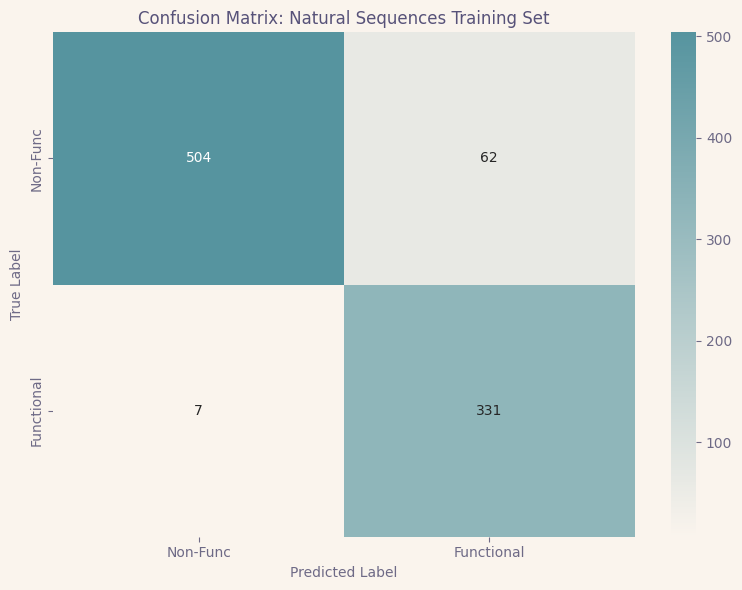

In [ ]:
rose_pine_colors = ['#faf4ed','#56949f']
cmap_pine = LinearSegmentedColormap.from_list("rose_pine_map", rose_pine_colors)

# Plot Natural Matrix
cm_nat = confusion_matrix(Y_train, Y_pred_train)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nat, annot=True, fmt='d', cmap=cmap_pine, xticklabels=['Non-Func', 'Functional'], yticklabels=['Non-Func', 'Functional'])
plt.title('Confusion Matrix: Natural Sequences Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix_training_set.png', dpi=300, bbox_inches='tight')
plt.show()

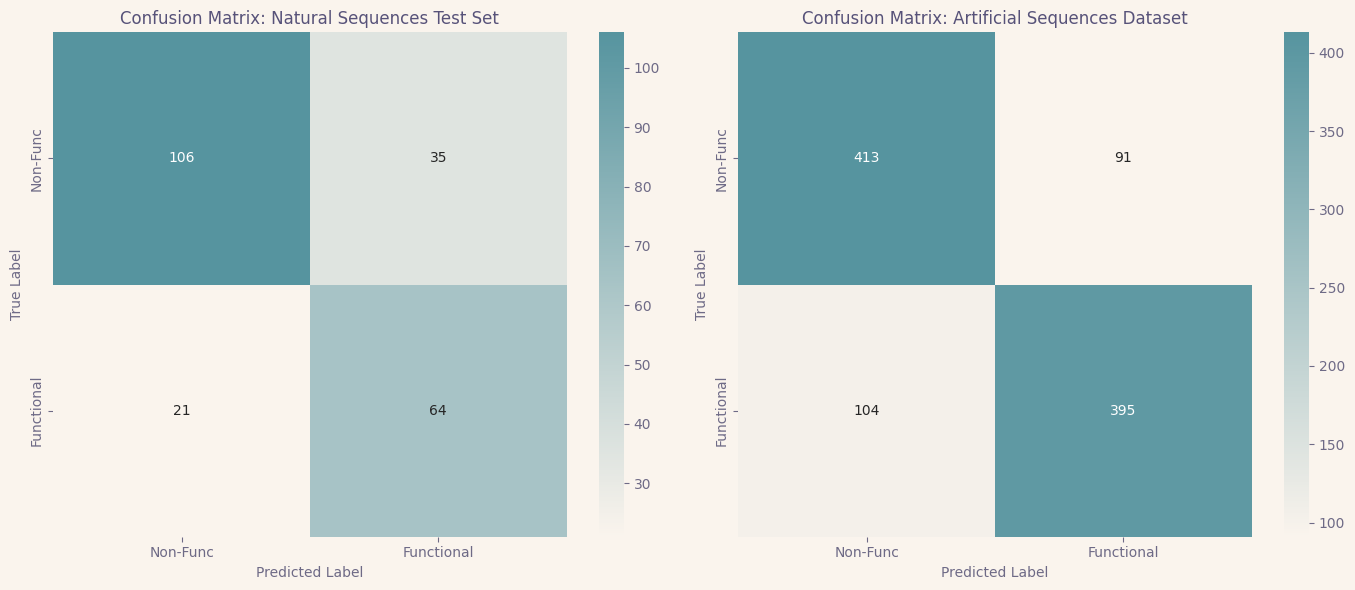

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Natural Matrix
cm_nat = confusion_matrix(Y_test, Y_pred)
sns.heatmap(cm_nat, annot=True, fmt='d', cmap=cmap_pine, ax=axes[0], xticklabels=['Non-Func', 'Functional'], yticklabels=['Non-Func', 'Functional'])
axes[0].set_title('Confusion Matrix: Natural Sequences Test Set')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Plot Artificial Matrix
cm_art = confusion_matrix(Y_art, Y_pred_art)
sns.heatmap(cm_art, annot=True, fmt='d', cmap=cmap_pine, ax=axes[1], xticklabels=['Non-Func', 'Functional'], yticklabels=['Non-Func', 'Functional'])
axes[1].set_title('Confusion Matrix: Artificial Sequences Dataset')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrix_test.png', dpi=300, bbox_inches='tight')
plt.show()

### Logistic Regression

In [ ]:
# Split the data into training (70%) and temporary (30%) sets
X_lr_train, X_lr_temp, y_lr_train, y_lr_temp = train_test_split(X_flat, Y, test_size=0.30, random_state=34)

# Further split the temporary set into test (15%) and validation (15%) sets
X_lr_test, X_lr_valid, y_lr_test, y_lr_valid = train_test_split(X_lr_temp, y_lr_temp, test_size=0.5, random_state=34)

# Print the number of samples in each set
print("Number of training samples: ", X_lr_train.shape[0])
print("Number of validation samples: ", X_lr_valid.shape[0])
print("Number of test samples: ", X_lr_test.shape[0])

Number of training samples:  791
Number of validation samples:  170
Number of test samples:  169


In [ ]:
print(len(X_lr_train[6,:]))

1920


### Selecting the best hyperparameters

In [ ]:
# initialize the model
lin_reg = LogisticRegression(random_state=0, solver='saga', penalty='elasticnet', max_iter=5000)

p_grid = {
    'l1_ratio': [0, 0.15, 0.25, 0.5, 0.75, 1],
    'C': [0.01, 0.05, 0.1, 0.5, 1]
}
#initialize grid search with 3-folds cross validation
"""
The following scikit-function explores sistematically a grid of hyperparameters by using cross-validation
framework to evaluate each combination of hyperparameters electing the one with the highest score.
The total amount of tested models is: 6*5=30
A logarithmic scale has been selected to choose the parameters' values, in particular C.

"""
#The following function compute ROC and AUC of each model
grid = GridSearchCV(lin_reg, p_grid, scoring='roc_auc', cv=3,verbose=4)


# fit the grid
grid.fit(X_lr_train, y_lr_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV 1/3] END ................C=0.01, l1_ratio=0;, score=0.807 total time=   3.8s
[CV 2/3] END ................C=0.01, l1_ratio=0;, score=0.882 total time=   2.8s
[CV 3/3] END ................C=0.01, l1_ratio=0;, score=0.878 total time=   3.1s
[CV 1/3] END .............C=0.01, l1_ratio=0.15;, score=0.758 total time=   2.9s
[CV 2/3] END .............C=0.01, l1_ratio=0.15;, score=0.821 total time=   2.6s
[CV 3/3] END .............C=0.01, l1_ratio=0.15;, score=0.821 total time=   1.6s
[CV 1/3] END .............C=0.01, l1_ratio=0.25;, score=0.722 total time=   1.2s
[CV 2/3] END .............C=0.01, l1_ratio=0.25;, score=0.780 total time=   1.4s
[CV 3/3] END .............C=0.01, l1_ratio=0.25;, score=0.755 total time=   0.8s
[CV 1/3] END ..............C=0.01, l1_ratio=0.5;, score=0.500 total time=   0.2s
[CV 2/3] END ..............C=0.01, l1_ratio=0.5;, score=0.500 total time=   0.2s
[CV 3/3] END ..............C=0.01, l1_ratio=0.5;

GridSearchCV(cv=3,
             estimator=LogisticRegression(max_iter=5000, penalty='elasticnet',
                                          random_state=0, solver='saga'),
             param_grid={'C': [0.01, 0.05, 0.1, 0.5, 1],
                         'l1_ratio': [0, 0.15, 0.25, 0.5, 0.75, 1]},
             scoring='roc_auc', verbose=4)

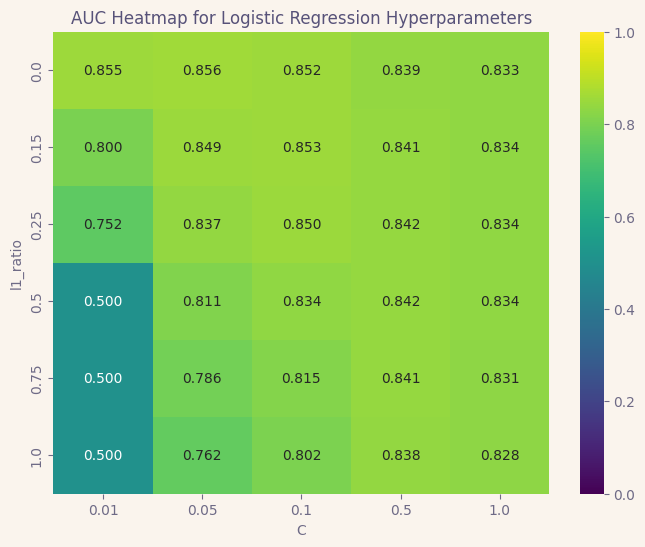

In [ ]:
"""
The following program plots the result of the search for the best hyperparameters:
each cell is the result of the mean AUC computed over 3fold-cross-validation.
The x axis is the C parameter, the y axis is the l1_ratio parameter
The brighter the color the better the model.

Pattern to observe:
-if a cell is [] for low C, but vice-versa, it means that the data show signal
that is eventually killed by a (too much) strong regolarization;
-if a cell is [] for high l1_ratio (heavy l1 norm) and vice-versa it means that there is a subset of
"more important feature" that contains the most informative ones;
-if cells have similar values it generally means the model is robust

"""


# save grid search result in a dataframe
results = pd.DataFrame(grid.cv_results_)

# prepare data for heatmap
heatmap = results.pivot_table(
    index='param_l1_ratio',
    columns='param_C',
    values='mean_test_score'
)

# grafico
plt.figure(figsize=(8,6))
sns.heatmap(heatmap, annot=True, fmt=".3f", vmin=0, vmax=1,cmap='viridis')
plt.xlabel("C")
plt.ylabel("l1_ratio")
plt.title("AUC Heatmap for Logistic Regression Hyperparameters")
plt.show()

### PROVVISORIO: REGR LINEARE NUOVA

ho usato l1_ratio=0.8, C=1 -> quelli teorici che trova il modello sarebbero l1_ratio=0 e C=0.05

In [ ]:
# Training the best model using the best hyperparameters read from the map above
best_lreg = LogisticRegression(random_state=0, solver='saga', penalty='elasticnet',l1_ratio=0.8,C=1, max_iter=5000).fit(X_lr_train,y_lr_train)

NameError: name 'LogisticRegression' is not defined

In [ ]:
#Code needed in the graph below

seq_len = 96
aa_letters = list("ACDEFGHIKLMNPQRSTVWY")  # 20 aminoacids

feature_names = []

for aa in aa_letters:
    for pos in range(1, seq_len + 1):
        feature_names.append(f"{pos}{aa}")

feature_names = np.array(feature_names)

print(len(feature_names))   # dovrebbe essere 1840
print(feature_names[:93])
print(feature_names[-10:])

1920
['1A' '2A' '3A' '4A' '5A' '6A' '7A' '8A' '9A' '10A' '11A' '12A' '13A'
 '14A' '15A' '16A' '17A' '18A' '19A' '20A' '21A' '22A' '23A' '24A' '25A'
 '26A' '27A' '28A' '29A' '30A' '31A' '32A' '33A' '34A' '35A' '36A' '37A'
 '38A' '39A' '40A' '41A' '42A' '43A' '44A' '45A' '46A' '47A' '48A' '49A'
 '50A' '51A' '52A' '53A' '54A' '55A' '56A' '57A' '58A' '59A' '60A' '61A'
 '62A' '63A' '64A' '65A' '66A' '67A' '68A' '69A' '70A' '71A' '72A' '73A'
 '74A' '75A' '76A' '77A' '78A' '79A' '80A' '81A' '82A' '83A' '84A' '85A'
 '86A' '87A' '88A' '89A' '90A' '91A' '92A' '93A']
['87Y' '88Y' '89Y' '90Y' '91Y' '92Y' '93Y' '94Y' '95Y' '96Y']


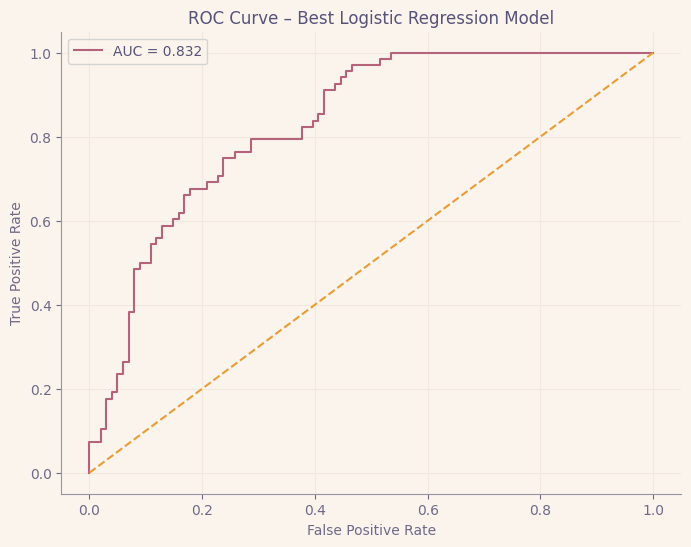

In [ ]:
# predict probability of the test set
proba = best_lreg.predict_proba(X_lr_test)[:, 1]

# rates
fpr, tpr, thr = roc_curve(y_lr_test, proba)

# auc scores
auc = roc_auc_score(y_lr_test, proba)

# compute best threshold for hard classification
J = tpr - fpr
best_idx = J.argmax()
best_threshold = thr[best_idx]

# plot roc curve
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Best Logistic Regression Model")
plt.legend()
plt.grid(True)
plt.savefig('ROC_curve_best_logisticmodel.png', dpi=300, bbox_inches='tight')
plt.show()

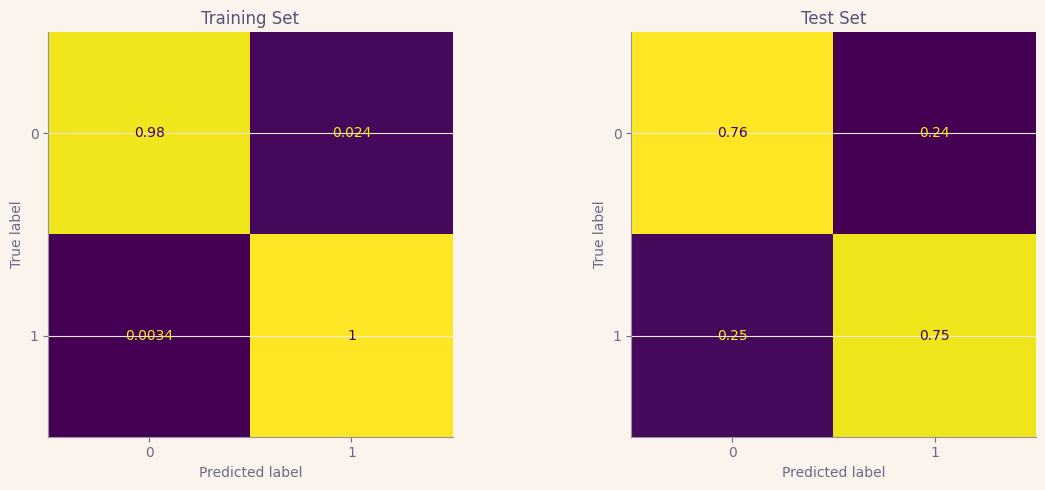

In [ ]:
# probability and hard classification on train
proba_train = best_lreg.predict_proba(X_lr_train)[:, 1]
y_pred_train = (proba_train >= best_threshold).astype(int)

# probability and hard classification on test
proba_val = best_lreg.predict_proba(X_lr_test)[:, 1]
y_pred_val = (proba_val >= best_threshold).astype(int)

# Confusion matrices
cm_train = confusion_matrix(y_lr_train, y_pred_train,normalize='true')
cm_val = confusion_matrix(y_lr_test, y_pred_val,normalize='true')

# Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train)
disp_train.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Training Set")

disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val)
disp_val.plot(ax=axes[1], colorbar=False)
axes[1].set_title("Test Set")
plt.savefig('confusion_matrices_lin_regl.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

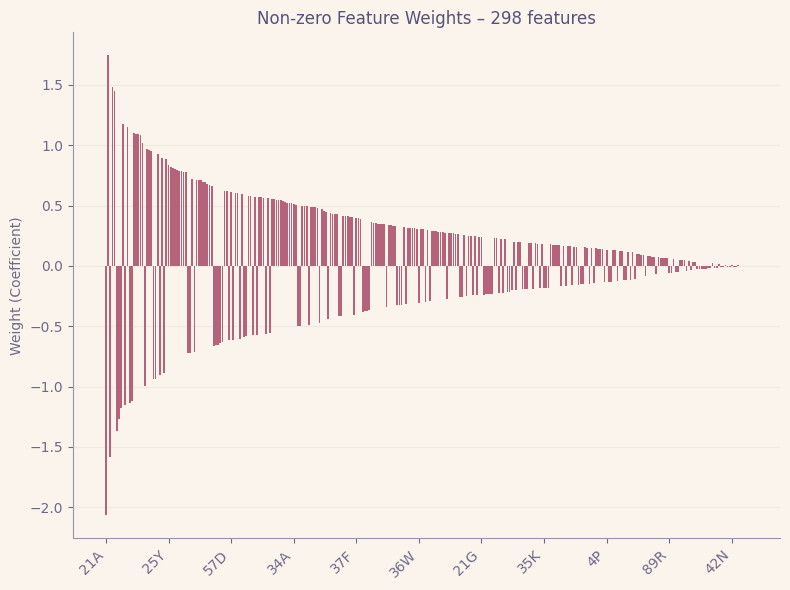

In [ ]:
# extract learned coefficients
coef = best_lreg.coef_.ravel()

# Keep only non-zero coefficients
ind = np.where(coef != 0)[0]
ref_coef_nonzero = coef[ind]
features_nonzero = feature_names[ind]

# Sort by absolute weight
idx_sorted = np.argsort(np.abs(ref_coef_nonzero))[::-1]
coef_sorted = ref_coef_nonzero[idx_sorted]
features_sorted = features_nonzero[idx_sorted]

# Plot
plt.figure(figsize=(8,6))
plt.bar(features_sorted, coef_sorted)

# Reduce x-ticks
step = max(1, len(features_sorted) // 10)
plt.xticks(range(0, len(features_sorted), step),
           features_sorted[::step],
           rotation=45,
           ha='right')

plt.ylabel("Weight (Coefficient)")
plt.title(f"Non-zero Feature Weights – {len(features_sorted)} features")
plt.tight_layout()
plt.savefig('nonzero_feature_weights.png', dpi=300, bbox_inches='tight')
plt.show()

PROBLEMA: IL MODELLO MANTIENE TROPPE CARATTERISTICHE, QUALCOSA E' ANDATO STORTO. SE NE AVESSE MANTENUTE UN ORDINE DI GRANDEZZA IN MENO AVREMMO POTUTO CONCLUDERE CHE MAGARI CI SONO POSIZIONI CRUCIALI ALL'INTERNO DELLA PROTEINA LE QUALI SONO LE PIU' SIGNIFICATIVE PER LA SUA FUNZIONALITA'

### PROVVISORIO: REGR LINEARE PRECEDENTE

In [ ]:
# Initialize and fit the logistic regression model on the training data
model_c = LogisticRegression()
model_c.fit(X_lr_train, y_lr_train)

# Make predictions on the validation set
y_lr_pred = model_c.predict(X_lr_valid)

# Calculate prediction probabilities
prob = model_c.predict_proba(X_lr_valid)

# Generate the confusion matrix
cm = confusion_matrix(y_lr_valid, y_lr_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_pine, xticklabels=['Non-Func', 'Functional'], yticklabels=['Non-Func', 'Functional'])
plt.title('Confusion Matrix: Natural Sequences Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion_matrix_training_set_logistic_regression.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'cmap_pine' is not defined

<Figure size 800x600 with 0 Axes>

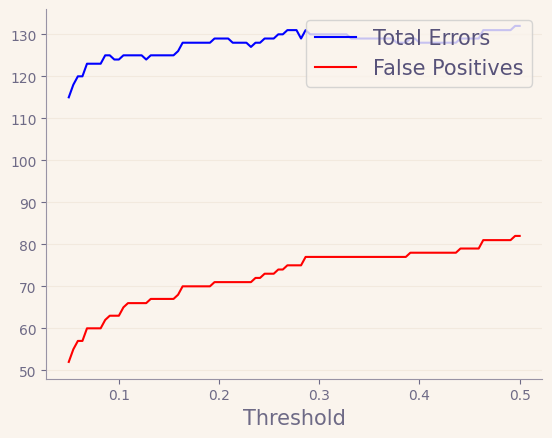

In [ ]:
# Initialize arrays to store total errors and false functional predictions
total_error = np.zeros(0)
fp = np.zeros(0)

# Generate a range of threshold values from 0.05 to 0.5, divided into 100 points
threshold = np.linspace(0.05, 0.5, 100)

# Iterate over each threshold value
for thr in threshold:
    # Initialize the array to store predictions based on the current threshold
    y_lr_treshold = np.zeros(X_lr_valid.shape[0])

    # Assign predictions based on the threshold comparison
    for i in range(len(y_lr_treshold)):
        if prob[i, 1] >= thr:
            y_lr_treshold[i] = False  # Predict "4" for positive class if probability exceeds threshold
        else:
            y_lr_treshold[i] = True  # Predict "2" for negative class otherwise

    # Compute the confusion matrix for the current threshold
    cm = confusion_matrix(y_lr_valid, y_lr_treshold)

    # Store the total number of errors (false positives + false negatives)
    total_error = np.append(total_error, cm[0, 1] + cm[1, 0])

    # Store the number of false negative predictions ("functionals" misclassified)
    fp = np.append(fp, cm[0, 1])

# Plot total errors and false healthy predictions against the threshold values
plt.plot(threshold, total_error, c='blue', label='Total Errors')
plt.plot(threshold, fp, c='red', label='False Positives')
plt.xlabel('Threshold', fontsize=15)
plt.legend(loc="upper right", fontsize=15);

In [ ]:
# Predict probabilities for the test set
prob = model_c.predict_proba(X_test)

# Initialize an array to store predictions based on the threshold
y_treshold = np.zeros(X_test.shape[0])

# Assign predictions using a threshold of 0.1
for i in range(len(prob)):
    if prob[i, 1] >= 0.1:
        y_treshold[i] = 4  # Predict "4" for the positive class if probability is 0.1 or higher
    else:
        y_treshold[i] = 2  # Predict "2" for the negative class otherwise

# Calculate and display the confusion matrix for the test set
cm = confusion_matrix(y_test, y_treshold)
disp = ConfusionMatrixDisplay(cm, display_labels=['healthy', 'cancer'])
disp.plot()

# Update plot settings for better readability
plt.rcParams.update({'font.size': 30})
plt.grid(False)
plt.show()

NameError: name 'model_c' is not defined

## Generating Artificial Sequences

### Defining the model VAE class and others utilities

In [ ]:
class VAE(nn.Module):
  """
  VAE implementation Pytrch
  """
#Hyperparameters -> architectural choises
  def __init__(self, seq_len=94, n_aa=21, embedding_dim = 16, latent_dim=32, hidden_dim=128):
      super().__init__()
      self.seq_len = seq_len # length of sequences to encode
      self.n_aa = n_aa # number of total avaiabe symbols that can appear in a protein (aminoacids + '-')
      self.embedding_dim = embedding_dim # embedding dimension (discrete symbols -> vectors)
      self.latent_dim = latent_dim # dimension of latent space
      self.hidden_dim = hidden_dim # dimension of hidden layer

      # Embedding layer
      self.embedding = nn.Embedding(n_aa, embedding_dim)

      # Encoder
      self.encoder = nn.Sequential(
          nn.Flatten(),
          nn.Linear(seq_len*embedding_dim, hidden_dim),
          nn.ReLU(),
      )

      # encoder head
      self.fc_mu = nn.Linear(hidden_dim, latent_dim)
      self.fc_unconstrained_std = nn.Linear(hidden_dim, latent_dim)

      # Decoder (outputs unormalized logits)
      self.decoder = nn.Sequential(
          nn.Linear(latent_dim, hidden_dim),
          nn.ReLU(),
          nn.Linear(hidden_dim, seq_len*n_aa)
      )

  def encode(self, x):
      e = self.embedding(x)  # (B, L, D)
      h = self.encoder(e) # (B, hidden_dim)
      mu = self.fc_mu(h) # (B, latent_dim)
      unconstrained_std = self.fc_unconstrained_std(h)
      std = F.softplus(unconstrained_std) + 1e-6 # (B, latent_dim)
      return mu, std

  def reparameterize(self, mu, std): #creates z sampled in a differentiable way
      eps = torch.randn_like(std)
      return mu + eps * std

  def decode(self, z): #coorect reshape
      out = self.decoder(z)
      return out.view(-1, self.seq_len, self.n_aa)
# the following function resturns logits, mu, std;
# whilw training the code uses logits for loss, mu/std per KL.

  def forward(self, x):
      mu, std = self.encode(x)
      z = self.reparameterize(mu, std)
      logits = self.decode(z)
      return logits, mu, std
# The following function from a standard gaussian prior, than decodes and takes
# the argmax for each position deterministically

  def generate(self, n=1):
      # Sample n latent vectors and send it to device
      z = torch.randn(n, self.latent_dim).to(next(self.parameters()).device)

      # Decode to get logits
      logits = self.decode(z)  # (n, seq_len, n_aa)

      sequences = logits.argmax(dim=-1)  # (n, seq_len)

      return sequences



In [ ]:
def vae_loss(logits, target, mu, std):
  """
  Loss function for the VAE
  logits.permute(0,2,1) does (B, A, L);
  target (B, L) indicates the correct class for each position.
  """
  # Reconstruction loss (cross-entropy)
  recon_loss = F.cross_entropy(
      logits.permute(0, 2, 1),
      target,
      reduction='sum'
  )

# NB: the total loss is -ELBO=recon_loss + kl_loss
  # KL divergence for diagonal Gaussian
  kl_loss = 0.5 * torch.sum(mu.pow(2) + std.pow(2) - 2*torch.log(std) - 1 )

  return recon_loss, kl_loss

### Model's training

In [ ]:
# HYPERPARAMETERS

# Training spec
# Parameters chosen by online research about the the values which work best
batch_size = 32 # the machinery is applied on this subset of the data for each of them
num_epochs = 100 # number of times the machinery is applied to the whole dataset

#Parameter for the future gradient descend

# LR schedule (cosine annealing)
initial_learning_rate = 1e-4 # Dinamyc learning rate, conservative values have been chosen
final_learning_rate = 1e-5

# Sthocastic gradient descend with momentum
momentum = 0.8

# Where to make computations
"""
If my computer has an NVIDIA GPU capable of running pytorch use that, instead use CPU
"""
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

# Loss printing option
print_interval = 20 #how often updates about the loss function will be printed

# DATASET
"""
Utility functions: I copy the data from the dataset and make them ready to be divided into butches with
a random shuffle included
"""
dataset = SequenceDataset(df_nat_raw.loc[:,1:])
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# MODEL

model = VAE(seq_len=dataset[0].shape[0], n_aa=21, embedding_dim = 16, latent_dim=8, hidden_dim=128).to(device)

# Optimization algorithm (GD) selection

optimizer = torch.optim.SGD(model.parameters(), lr=initial_learning_rate, momentum=momentum)
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=final_learning_rate)

# TRAINING ITER

# Initialization of losses' history
recon_losses_history = []
kl_losses_history = []
total_losses_history = []

for epoch in range(1, num_epochs + 1):
    model.train()
    batch_recon = 0.0
    batch_kl = 0.0
    batch_loss = 0.0

    for batch in dataloader:
        x = batch.to(device)
        optimizer.zero_grad()
        logits, mu, std = model(x)

        recon_loss, kl_loss = vae_loss(logits, x, mu, std)
        loss = recon_loss + kl_loss
        loss.backward()
        optimizer.step()

        # Accumulate sums
        batch_recon += recon_loss.item()
        batch_kl += kl_loss.item()
        batch_loss += loss.item()

    # Averaging over the dataset
    avg_recon = batch_recon / len(dataset)
    avg_kl = batch_kl / len(dataset)
    avg_total = batch_loss / len(dataset)

    # Variables for later plots
    recon_losses_history.append(avg_recon)
    kl_losses_history.append(avg_kl)
    total_losses_history.append(avg_total)

    # Printing the state of the ongoing process
    if epoch % print_interval == 0:
        print(f"Epoch {epoch}/{num_epochs} | "
              f"Recon Loss: {avg_recon:.4f} | "
              f"KL Loss: {avg_kl:.4f} | "
              f"Total Loss: {avg_total:.4f} |"
              f"lr: {scheduler.get_last_lr()[0]}"
             )

    # advance learning rate
    scheduler.step()

device: cpu


/tmp/ipython-input-2751146723.py:46: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



Epoch 20/100 | Recon Loss: 129.1052 | KL Loss: 12.3329 | Total Loss: 141.4381 |lr: 9.221862584235533e-05
Epoch 40/100 | Recon Loss: 113.6363 | KL Loss: 13.5441 | Total Loss: 127.1804 |lr: 7.024320641103818e-05
Epoch 60/100 | Recon Loss: 104.2897 | KL Loss: 14.3736 | Total Loss: 118.6633 |lr: 4.2445400228234734e-05
Epoch 80/100 | Recon Loss: 99.2545 | KL Loss: 14.7502 | Total Loss: 114.0047 |lr: 1.944302444309395e-05
Epoch 100/100 | Recon Loss: 97.0106 | KL Loss: 14.8855 | Total Loss: 111.8960 |lr: 1.002220478354208e-05


### Plot of the Loss functions

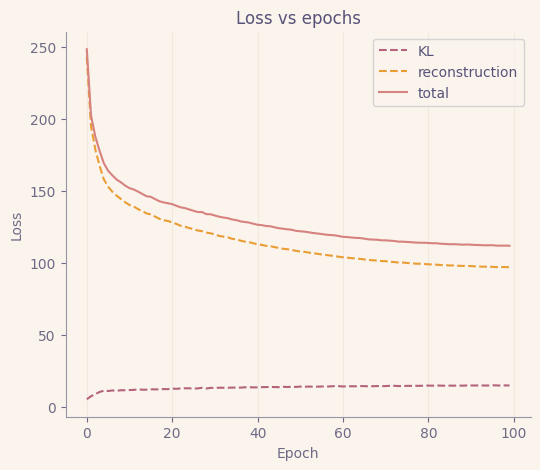

In [ ]:
# the following is the plot of the loss function
epochs = list(range(num_epochs))
plt.figure(figsize=(6, 5))
plt.plot(epochs, kl_losses_history, label='D_kl',linestyle='--')
plt.plot(epochs, recon_losses_history, label='reconstruction',linestyle='--')
plt.plot(epochs, total_losses_history, label='total',linestyle='-')
plt.grid()
plt.xlabel('Epoch')
plt.ylabel('Loss function')
plt.title('Loss vs epochs')
plt.legend()
plt.savefig('loss_vs_epochs.png', dpi=300, bbox_inches='tight')
plt.show()

## Objective Function and Interpretation of the Training Loss Curves

A Variational Autoencoder (VAE) is trained by maximizing the Evidence Lower Bound (ELBO).
Equivalently, it minimizes the negative ELBO:

$$
\mathcal{L} = \mathcal{L}_{\text{rec}} + \mathcal{L}_{\text{KL}}
$$

where the reconstruction loss is

$$
\mathcal{L}_{\text{rec}} =
\mathbb{E}_{q_\phi(z \mid x)} \left[ -\log p_\theta(x \mid z) \right]
$$

and the KL divergence term is

$$
\mathcal{L}_{\text{KL}} =
D_{\mathrm{KL}}\left(q_\phi(z \mid x)\,\|\,p(z)\right).
$$

The reconstruction term encourages accurate reconstruction of the input data,
while the KL term regularizes the latent space by pushing the approximate posterior
towards the prior distribution \( p(z) = \mathcal{N}(0, I) \).

During training, three curves are observed: reconstruction loss, KL divergence,
and total loss. The KL divergence rapidly saturates,
while the reconstruction and total losses decrease smoothly and remain almost overlapping.

This behavior indicates that the KL term contributes very little to the total loss.
As a consequence, the encoder learns posterior distributions close to the prior,
making the latent variable \( z \) almost independent of the input \( x \).
This phenomenon is known as **posterior collapse**.

Although the reconstruction loss decreases, indicating improved decoding,
the latent space fails to capture meaningful structure in the data.
The model therefore behaves more like a deterministic autoencoder
than a fully expressive variational autoencoder.


### Sampling from the distribution

In [ ]:
# Utilities

def one_hot_seq(df_sequences):
  """
  This function encodes a matrix whose columns are protein sequences in ohe
  """
  amino_acids = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K',
                  'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']

  one_hot_list = []
  for col in df_sequences.columns:
      dummies = pd.get_dummies(df_sequences[col])
      # Keep only the 20 amino acids and ignore '-'
      dummies = dummies.reindex(columns=amino_acids, fill_value=0)
      # Rename columns with position prefix
      dummies.columns = [f"pos{col}_{aa}" for aa in amino_acids]
      one_hot_list.append(dummies.astype(int))

  df_sequences_one_hot = pd.concat(one_hot_list, axis=1)
  return df_sequences_one_hot


# set to evaluation mode
model.eval()

# generate sequences
with torch.no_grad():
    seq_numeric = model.generate(n=1130).numpy()

# convert to list of amminoacid
vectorized_map = np.vectorize(n_to_aa.get)
sampled_seq = vectorized_map(seq_numeric)

# convert to dataframe
df_smp_X = pd.DataFrame(sampled_seq,columns=list(range(1,97)))

# one hot encode it
df_smp_X = one_hot_seq(df_smp_X)

# Get predicted probabilities for the positive class
#y_prob = model_c.predict_proba(df_smp_X)[:, 1]
y_prob= best_lreg.predict_proba(df_smp_X)[:, 1]

# Apply custom threshold
y_sampled = (y_prob >= best_threshold).astype(int)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning:

X has feature names, but LogisticRegression was fitted without feature names



### Sample analysis

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning:

X has feature names, but PCA was fitted without feature names



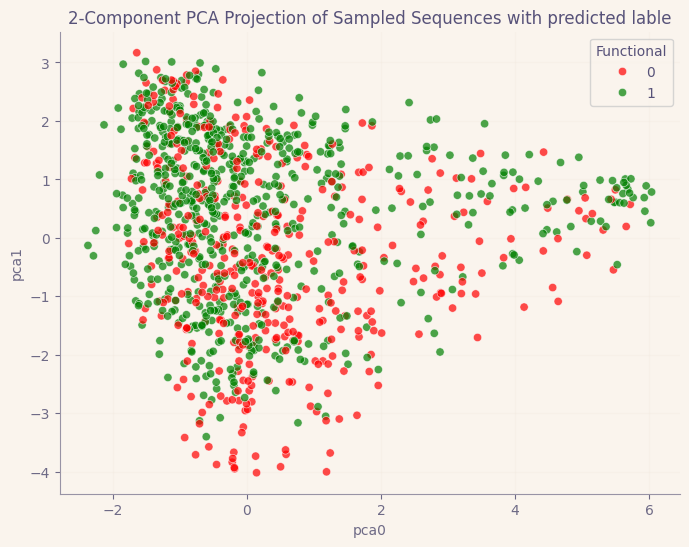

In [ ]:
def perform_pca_pandas(X_smp, X_nat, n_components=2):
    """
    Proietta i dati campionati X_smp sulle componenti principali
    dei dati naturali X_nat e restituisce un DataFrame Pandas.

    X_smp: array-like o DataFrame delle sequenze campionate (artificiali)
    X_nat: array-like o DataFrame delle sequenze naturali (per calcolare PCA)
    n_components: numero di componenti principali
    """

    # Inizializza PCA
    pca = PCA(n_components=n_components).set_output(transform="pandas")

    # Fit sui dati naturali
    pca.fit(X_nat)

    # Trasforma i dati artificiali
    df_pca = pca.transform(X_smp)

    return df_pca




# project sampled sequences on
df_X_sampled_2c = perform_pca_pandas(df_smp_X,X_flat, 2)

# add label
df_X_sampled_2c['Functional'] = y_sampled

# plot
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_X_sampled_2c,
    x='pca0', y='pca1',
    hue='Functional',
    palette=['red','green'],
    alpha=0.7
)
plt.title('2-Component PCA Projection of Sampled Sequences with predicted lable')
plt.grid(alpha=0.3)
plt.savefig('2-Components_PCA_Projection_of_sampled_sequences.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Concatenate the two dataframes
df_X_nat = pd.DataFrame(X_flat)
df_X_art = pd.DataFrame(X_art_flat)

df_X_nat.columns = df_smp_X.columns
df_X_art.columns = df_smp_X.columns

df_X_concat = pd.concat([df_X_nat, df_X_art,df_smp_X], ignore_index=True)

#print(df_smp_X)
#print(df_X_art)
#print(df_X_nat)

FIN QUI TUTTO CORRETTO, QUELLI A SEGUIRE MI DANNO ANCORA QUALCHE BIZZA

### PCA 2-components with cluster labels

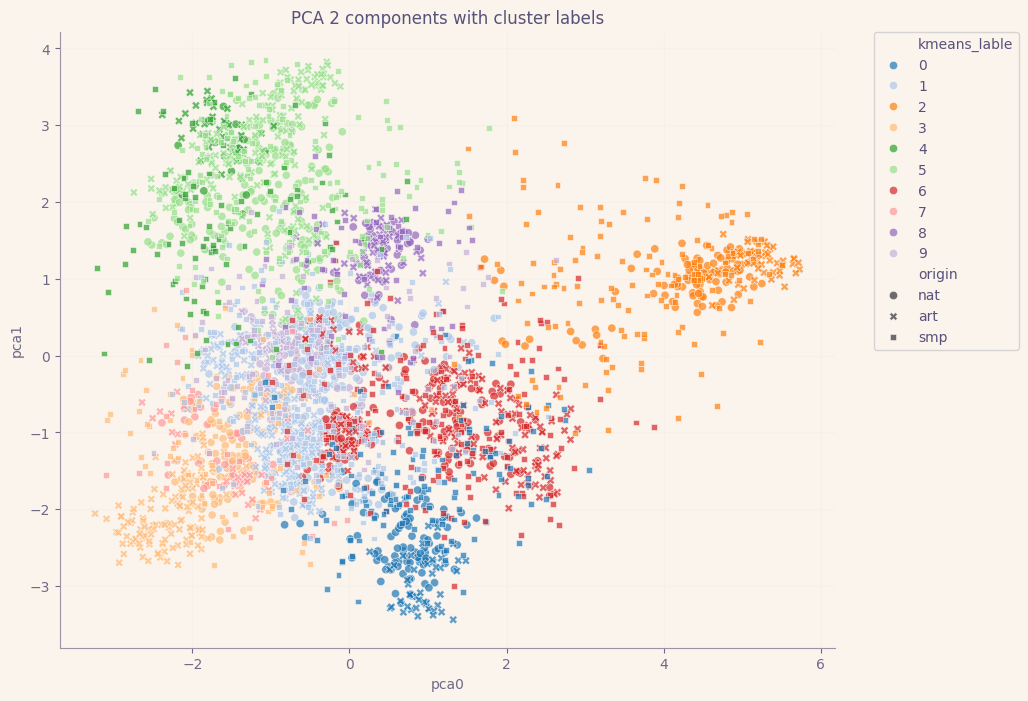

In [ ]:
# add to the label information about the origin
df_nat_y = pd.DataFrame({'y': Y})
df_art_y = pd.DataFrame({'y': Y_art})
df_smp_y = pd.DataFrame({'y': y_sampled})

df_nat_y['origin'] = 'nat'
df_art_y['origin'] = 'art'
df_smp_y['origin'] = 'smp'

df_y = pd.concat([df_nat_y, df_art_y, df_smp_y], ignore_index=True)


# initialize kmeans with k = 10A
kmeans = KMeans(n_clusters=10, random_state=0).fit(df_X_concat)

# get cluster labels
kmeans_labels = kmeans.labels_

# PCA 200 components - useful for speading t-sne up
pca = PCA(n_components=200).set_output(transform="pandas")
df_X_pca_200 = pca.fit_transform(df_X_concat)


# PCA 2 components
pca = PCA(n_components=2).set_output(transform="pandas")
df_X_pca_2 = pca.fit_transform(df_X_concat)

# t-SNE 2 components
tsne = TSNE(init='random', perplexity=30, n_components=2, random_state=0).set_output(transform="pandas")
df_X_tsne_2 = tsne.fit_transform(df_X_pca_200)

# add labels
df_X_pca_2['Functional'] = df_y['y']
df_X_pca_2['origin'] = df_y['origin']
df_X_pca_2['kmeans_lable'] = kmeans_labels
df_X_tsne_2['Functional'] = df_y['y']
df_X_tsne_2['origin'] = df_y['origin']
df_X_tsne_2['kmeans_lable'] = kmeans_labels

# Plot
plt.figure(figsize=(10,8))
sns.scatterplot(
    data=df_X_pca_2,
    x='pca0', y='pca1',
    hue='kmeans_lable',
    style='origin',
    palette='tab20',
    alpha=0.7,
)
plt.title('PCA 2 components with cluster labels')
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()

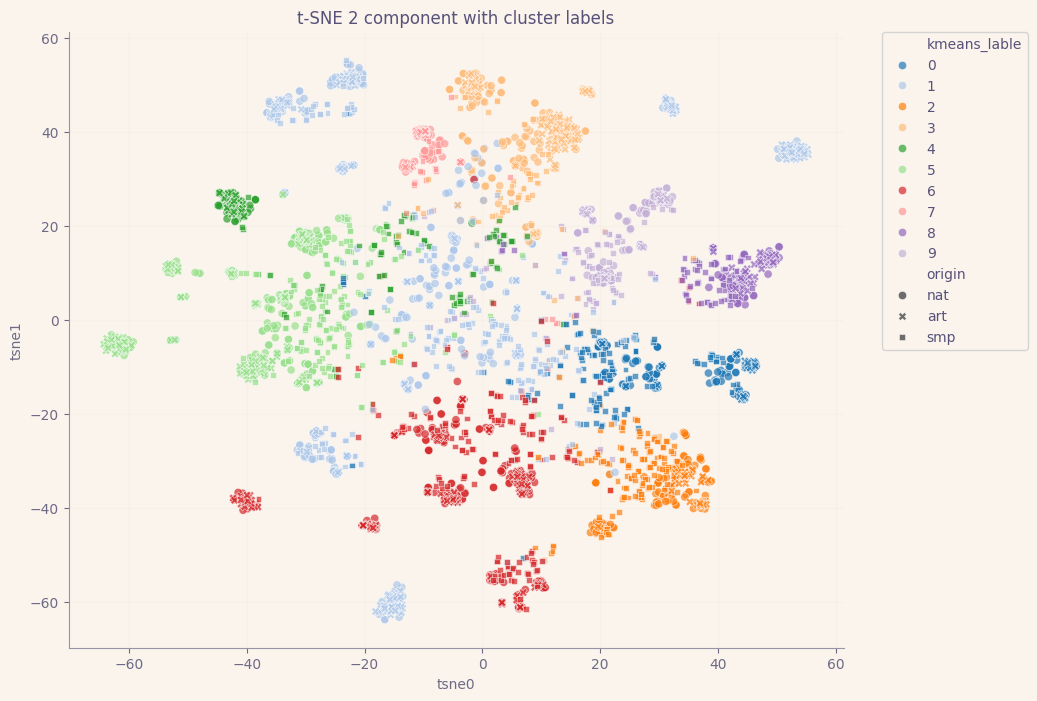

In [ ]:
plt.figure(figsize=(10,8))
sns.scatterplot(
    data=df_X_tsne_2,
    x='tsne0', y='tsne1',
    hue='kmeans_lable',
    style='origin',
    palette='tab20',
    alpha=0.7,
)
plt.title('t-SNE 2 component with cluster labels')
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()


CONCLUSIONS: the sequences sampled are good rapresentatives, indeed, when projected on natural sequences components from the dataset, they are barely distinguishable. Furthemore, when clustering algorithms are applied no new cluster of generated-only sequences appear, the clustering structure resembles the natural one.